In [1]:
# Parameters
BATCH_MODE = "true"


# App-1 : Le Problème des N-Reines

**Navigation** : [Index](../README.md) | [Part2-CSP](../Part2-CSP/README.md) | [App-2 GraphColoring >>](App-2-GraphColoring.ipynb)

## Objectifs d'apprentissage

A la fin de ce notebook, vous saurez :
1. **Formaliser** le problème des N-Reines comme un CSP (variables, domaines, contraintes) -- *Bloom : Comprendre*
2. **Implementer** un solveur par backtracking avec heuristiques (MRV, Forward Checking) -- *Bloom : Appliquer*
3. **Comparer** backtracking, min-conflicts et OR-Tools CP-SAT sur différentes tailles -- *Bloom : Analyser*
4. **Evaluer** les forces et limites de chaque approche selon la taille du problème -- *Bloom : Evaluer*

### Prerequis
- Python 3.10+, matplotlib, numpy, ortools
- [CSP-1 : Fundamentals](../Part2-CSP/CSP-1-Fundamentals.ipynb) -- backtracking, MRV, formalisme CSP

### Duree estimee : 30 minutes

***

## 1. Introduction (~3 min)

Le problème des **N-Reines** est l'un des benchmarks les plus celebres en informatique et en intelligence artificielle. L'enonce est simple :

> Placer $N$ reines sur un echiquier $N \times N$ de sorte qu'aucune paire de reines ne s'attaque mutuellement (ni même ligne, ni même colonne, ni même diagonale).

### Historique

| Date | Auteur | Contribution |
|------|--------|--------------|
| 1848 | Max Bezzel | Pose le problème pour N=8 dans un journal d'echecs |
| 1850 | Franz Nauck | Première solution complète et generalisation a N reines |
| 1874 | S. Gunther & J.W.L. Glaisher | Première approche systématique par determinants |
| 1992 | Sosic & Gu | Min-Conflicts : resolution quasi-lineaire en temps |

### Pourquoi ce problème est important

- **Benchmark CSP** : il sert a evaluer les algorithmes de satisfaction de contraintes
- **Scalabilite** : l'espace de recherche croit exponentiellement ($N^N$ naif), mais des algorithmes intelligents resolvent $N = 10^6$ en secondes
- **Pedagogie** : il illustre parfaitement la différence entre recherche systématique et recherche locale

In [2]:
# Imports pour tout le notebook
import sys
import time
import random
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import os

# Helpers partages de la serie Search
# sys.path.insert(0, os.path.abspath('..'))
# from search_helpers import benchmark_table, plot_benchmark

# Seed pour reproductibilite
random.seed(42)
np.random.seed(42)

print("Imports OK")

Imports OK


***

## 2. Formulation comme CSP (~5 min)

### Modelisation

La cle d'une resolution efficace est de choisir une bonne representation. Puisque chaque colonne doit contenir exactement une reine, on utilise :

| Composant CSP | Définition | Taille |
|---------------|------------|--------|
| **Variables** | $Q_0, Q_1, \ldots, Q_{N-1}$ (une par colonne) | $N$ |
| **Domaines** | $D_i = \{0, 1, \ldots, N-1\}$ (numéro de ligne) | $N$ valeurs chacun |
| **Contraintes** | Pour tout $i \neq j$ : $Q_i \neq Q_j$ et $\vert i - j\vert \neq \vert Q_i - Q_j\vert$ | $\binom{N}{2}$ paires |

### Espace de recherche

| Representation | Taille | Explication |
|----------------|--------|-------------|
| Naive (case libre) | $\binom{N^2}{N}$ | Combinaisons de N cases parmi $N^2$ |
| Une reine par colonne | $N^N$ | Chaque colonne choisit une ligne |
| Permutation | $N!$ | Contrainte AllDifferent sur les lignes |

Pour $N = 8$ : $N^N = 16\,777\,216$ tandis que $N! = 40\,320$ -- un facteur de reduction de 416x rien qu'avec la modelisation.

### Contraintes detaillees

Pour deux reines aux colonnes $i$ et $j$ (avec $i < j$), il faut :

$$Q_i \neq Q_j \quad \text{(pas même ligne)}$$
$$|Q_i - Q_j| \neq |i - j| \quad \text{(pas même diagonale)}$$

La contrainte de colonne est déjà satisfaite par construction (une variable par colonne).

Implementons d'abord une fonction de visualisation de l'echiquier, puis verifions visuellement une solution connue pour $N = 8$.

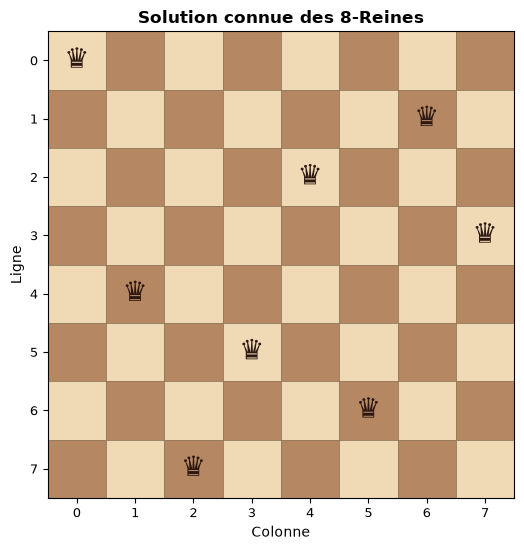

In [3]:
def draw_queens(queens, n=None, title="Solution N-Reines", ax=None):
    """Visualise un placement de reines sur un echiquier.

    Args:
        queens: liste ou dict (col -> row). queens[col] = row.
        n: taille de l'echiquier (deduit de queens si None).
        title: titre du graphique.
        ax: axes matplotlib (cree une nouvelle figure si None).
    """
    if isinstance(queens, dict):
        queens_list = [queens[c] for c in sorted(queens.keys())]
    else:
        queens_list = list(queens)

    if n is None:
        n = len(queens_list)

    if ax is None:
        fig, ax = plt.subplots(figsize=(max(5, n * 0.7), max(5, n * 0.7)))
    else:
        fig = ax.figure

    # Dessiner l'echiquier
    for row in range(n):
        for col in range(n):
            color = '#F0D9B5' if (row + col) % 2 == 0 else '#B58863'
            rect = patches.Rectangle((col, n - 1 - row), 1, 1,
                                     facecolor=color, edgecolor='#8B7355',
                                     linewidth=0.5)
            ax.add_patch(rect)

    # Placer les reines
    for col, row in enumerate(queens_list):
        ax.text(col + 0.5, n - 1 - row + 0.5, '\u265B',
                ha='center', va='center',
                fontsize=max(8, 28 - n),
                color='#2C1810')

    # Lignes d'attaque (pour petits echiquiers)
    conflicts = []
    for i in range(len(queens_list)):
        for j in range(i + 1, len(queens_list)):
            ri, rj = queens_list[i], queens_list[j]
            if ri == rj or abs(ri - rj) == abs(i - j):
                conflicts.append((i, ri, j, rj))

    for ci, ri, cj, rj in conflicts:
        ax.plot([ci + 0.5, cj + 0.5],
                [n - 1 - ri + 0.5, n - 1 - rj + 0.5],
                'r-', linewidth=2, alpha=0.6)

    ax.set_xlim(0, n)
    ax.set_ylim(0, n)
    ax.set_aspect('equal')
    ax.set_xticks([i + 0.5 for i in range(n)])
    ax.set_yticks([i + 0.5 for i in range(n)])
    ax.set_xticklabels(range(n), fontsize=9)
    ax.set_yticklabels(range(n - 1, -1, -1), fontsize=9)
    ax.set_xlabel('Colonne', fontsize=10)
    ax.set_ylabel('Ligne', fontsize=10)
    ax.set_title(title, fontsize=12, fontweight='bold')

    n_conflicts = len(conflicts)
    if n_conflicts > 0:
        ax.text(n / 2, -0.5, f'{n_conflicts} conflit(s) detecte(s)',
                ha='center', color='red', fontsize=10, fontweight='bold')

    return fig


# Afficher une solution connue pour N=8
known_solution_8 = [0, 4, 7, 5, 2, 6, 1, 3]
draw_queens(known_solution_8, title="Solution connue des 8-Reines")
plt.tight_layout()
plt.show()

### Interpretation : visualisation de la solution

**Sortie obtenue** : l'echiquier affiche 8 reines sans aucune ligne d'attaque rouge, confirmant que le placement `[0, 4, 7, 5, 2, 6, 1, 3]` est une solution valide.

| Verification | Résultat |
|-------------|----------|
| Lignes distinctes | Oui (0, 1, 2, 3, 4, 5, 6, 7 -- une permutation) |
| Colonnes distinctes | Oui (par construction : une reine par colonne) |
| Diagonales | Aucune paire en attaque diagonale |

> **Remarque** : pour $N = 8$, il existe exactement **92 solutions distinctes** (12 fondamentales sous symetries). Nous les enumererons dans la section CP-SAT.

***

## 3. Approche 1 : Backtracking (~7 min)

Le backtracking est la méthode de reference pour les CSP. Nous allons implementer trois variantes de complexite croissante :

1. **Backtracking simple** : exploration brute, colonne par colonne
2. **Avec heuristique MRV** : choisir la colonne au domaine le plus restreint
3. **Avec Forward Checking** : propager les contraintes pour reduire les domaines

### 3.1 Backtracking simple

L'algorithme place une reine dans chaque colonne de gauche a droite. Pour chaque ligne candidate, il verifie si la reine est en conflit avec les reines déjà placees.

In [4]:
def is_safe(queens, col, row):
    """Verifie si placer une reine en (col, row) est compatible
    avec les reines deja placees dans queens[0..col-1]."""
    for c in range(col):
        r = queens[c]
        if r == row:                          # meme ligne
            return False
        if abs(c - col) == abs(r - row):      # meme diagonale
            return False
    return True


def backtracking_simple(n):
    """Backtracking simple pour N-Reines.

    Parcourt les colonnes de gauche a droite.
    Retourne (solution, nodes_explored).
    """
    queens = [0] * n
    nodes = [0]  # compteur mutable

    def solve(col):
        if col == n:
            return True
        for row in range(n):
            nodes[0] += 1
            if is_safe(queens, col, row):
                queens[col] = row
                if solve(col + 1):
                    return True
        return False

    if solve(0):
        return queens[:], nodes[0]
    return None, nodes[0]


# Test rapide sur N=8
sol, nodes = backtracking_simple(8)
print(f"Solution 8-Reines : {sol}")
print(f"Noeuds explores   : {nodes}")

Solution 8-Reines : [0, 4, 7, 5, 2, 6, 1, 3]
Noeuds explores   : 876


### 3.2 Avec heuristique MRV

L'heuristique **MRV** (Minimum Remaining Values) choisit a chaque étape la variable (colonne) dont le domaine restant est le plus petit. C'est la stratégie **fail-first** : on detecte les impasses le plus tot possible.

Pour N-Reines, cela signifie choisir la colonne qui a le moins de lignes viables.

In [5]:
def backtracking_mrv(n):
    """Backtracking avec heuristique MRV pour N-Reines.

    Retourne (solution_dict, nodes_explored).
    """
    domains = {col: set(range(n)) for col in range(n)}
    assignment = {}
    nodes = [0]

    def get_viable(col):
        """Retourne les lignes viables pour une colonne."""
        viable = []
        for row in domains[col]:
            ok = True
            for c2, r2 in assignment.items():
                if r2 == row or abs(c2 - col) == abs(r2 - row):
                    ok = False
                    break
            if ok:
                viable.append(row)
        return viable

    def solve():
        if len(assignment) == n:
            return True

        # MRV : choisir la colonne avec le moins de valeurs viables
        unassigned = [c for c in range(n) if c not in assignment]
        col = min(unassigned, key=lambda c: len(get_viable(c)))

        for row in get_viable(col):
            nodes[0] += 1
            assignment[col] = row
            if solve():
                return True
            del assignment[col]
        return False

    if solve():
        result = [assignment[c] for c in range(n)]
        return result, nodes[0]
    return None, nodes[0]


sol_mrv, nodes_mrv = backtracking_mrv(8)
print(f"Solution (MRV)    : {sol_mrv}")
print(f"Noeuds explores   : {nodes_mrv}")

Solution (MRV)    : [0, 4, 7, 5, 2, 6, 1, 3]
Noeuds explores   : 75


### 3.3 Avec Forward Checking

Le **Forward Checking** va plus loin que MRV : a chaque assignation, il propage immediatement les contraintes pour retirer des domaines des variables non assignees toute valeur rendue impossible. Si un domaine devient vide, on backtrack immediatement sans explorer le sous-arbre.

| Technique | Quand detecte-t-on l'echec ? |
|-----------|------------------------------|
| Backtracking simple | Au moment ou on essaie une valeur |
| Forward Checking | Des qu'un domaine voisin devient vide |

In [6]:
def backtracking_fc(n):
    """Backtracking avec Forward Checking pour N-Reines.

    Retourne (solution, nodes_explored).
    """
    queens = [None] * n
    # domains[col] = ensemble des lignes encore possibles
    domains = [set(range(n)) for _ in range(n)]
    nodes = [0]

    def forward_check(col, row):
        """Retire les valeurs inconsistantes des domaines futurs.
        Retourne la liste des reductions effectuees (pour restauration)."""
        pruned = []
        for c2 in range(n):
            if queens[c2] is not None or c2 == col:
                continue
            # Retirer la meme ligne
            if row in domains[c2]:
                domains[c2].remove(row)
                pruned.append((c2, row))
            # Retirer les diagonales
            d = abs(c2 - col)
            for diag_row in [row - d, row + d]:
                if 0 <= diag_row < n and diag_row in domains[c2]:
                    domains[c2].remove(diag_row)
                    pruned.append((c2, diag_row))
        return pruned

    def restore(pruned):
        """Restaure les valeurs retirees."""
        for c, r in pruned:
            domains[c].add(r)

    def solve(col_idx):
        if col_idx == n:
            return True

        # MRV : choisir la colonne non assignee au domaine le plus petit
        unassigned = [c for c in range(n) if queens[c] is None]
        col = min(unassigned, key=lambda c: len(domains[c]))

        for row in list(domains[col]):
            nodes[0] += 1
            queens[col] = row
            old_domain = domains[col].copy()
            domains[col] = set()  # assignee

            pruned = forward_check(col, row)

            # Verifier qu'aucun domaine futur n'est vide
            empty = any(len(domains[c]) == 0
                        for c in range(n) if queens[c] is None)

            if not empty and solve(col_idx + 1):
                return True

            # Restauration
            restore(pruned)
            domains[col] = old_domain
            queens[col] = None

        return False

    if solve(0):
        return queens[:], nodes[0]
    return None, nodes[0]


sol_fc, nodes_fc = backtracking_fc(8)
print(f"Solution (FC+MRV) : {sol_fc}")
print(f"Noeuds explores   : {nodes_fc}")

Solution (FC+MRV) : [0, 4, 7, 5, 2, 6, 1, 3]
Noeuds explores   : 75


### 3.4 Benchmark des variantes de backtracking

Comparons les trois variantes sur différentes tailles de problème. Le nombre de noeuds explores et le temps d'exécution mesurent l'efficacite.

In [7]:
def run_benchmark_bt(sizes):
    """Benchmark des trois variantes de backtracking."""
    results = {name: {'nodes': [], 'times': []}
               for name in ['Simple', 'MRV', 'FC+MRV']}

    solvers = [
        ('Simple', backtracking_simple),
        ('MRV', backtracking_mrv),
        ('FC+MRV', backtracking_fc),
    ]

    print(f"{'N':>4}  {'Simple':>12} {'MRV':>12} {'FC+MRV':>12}   (noeuds explores)")
    print("-" * 60)

    for n in sizes:
        row = f"{n:>4}"
        for name, solver in solvers:
            t0 = time.time()
            sol, nodes = solver(n)
            elapsed = time.time() - t0
            results[name]['nodes'].append(nodes)
            results[name]['times'].append(elapsed * 1000)
            row += f"  {nodes:>12}"
        print(row)

    return results


bt_sizes = [4, 8, 12, 16]
bt_results = run_benchmark_bt(bt_sizes)

   N        Simple          MRV       FC+MRV   (noeuds explores)
------------------------------------------------------------
   4            26             8             8
   8           876            75            75
  12          3066           153           153


  16        160712            44            39


Tracons les résultats en echelle logarithmique pour mieux apprecier les différences entre variantes.

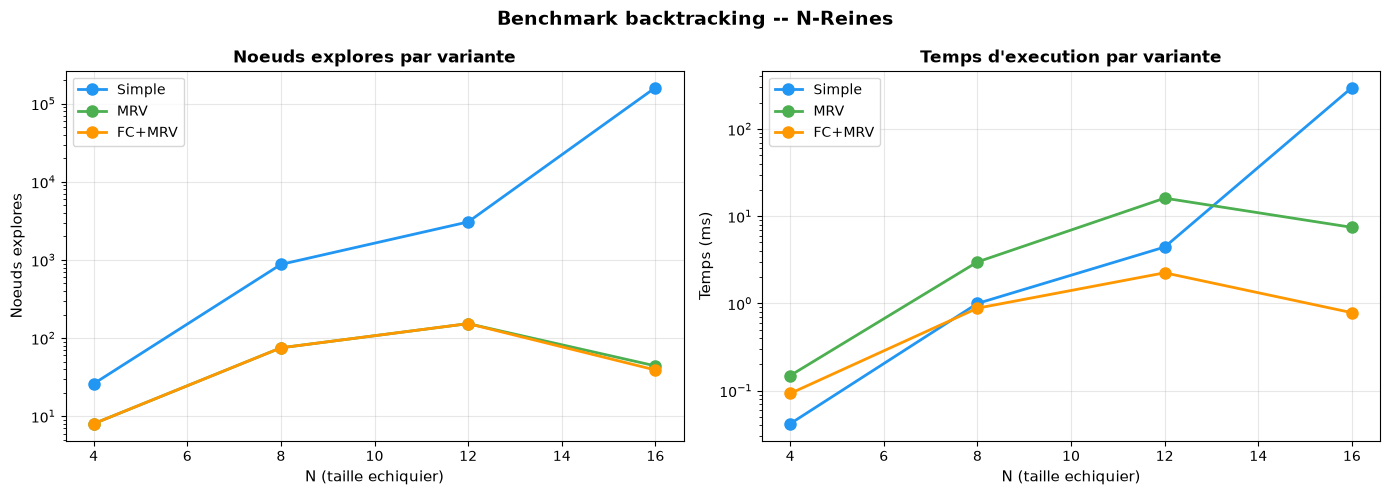

In [8]:
# Visualisation comparative
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = {'Simple': '#2196F3', 'MRV': '#4CAF50', 'FC+MRV': '#FF9800'}

# Noeuds explores (echelle log)
for name in ['Simple', 'MRV', 'FC+MRV']:
    axes[0].plot(bt_sizes, bt_results[name]['nodes'],
                 'o-', label=name, color=colors[name], linewidth=2, markersize=8)
axes[0].set_xlabel('N (taille echiquier)', fontsize=11)
axes[0].set_ylabel('Noeuds explores', fontsize=11)
axes[0].set_title('Noeuds explores par variante', fontweight='bold')
axes[0].set_yscale('log')
axes[0].legend(fontsize=10)
axes[0].grid(True, alpha=0.3)

# Temps d'execution
for name in ['Simple', 'MRV', 'FC+MRV']:
    axes[1].plot(bt_sizes, bt_results[name]['times'],
                 'o-', label=name, color=colors[name], linewidth=2, markersize=8)
axes[1].set_xlabel('N (taille echiquier)', fontsize=11)
axes[1].set_ylabel('Temps (ms)', fontsize=11)
axes[1].set_title('Temps d\'execution par variante', fontweight='bold')
axes[1].set_yscale('log')
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3)

plt.suptitle('Benchmark backtracking -- N-Reines', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### Interpretation : benchmark backtracking

**Sortie obtenue** : le nombre de noeuds et le temps augmentent exponentiellement avec $N$, mais les heuristiques reduisent fortement l'exploration.

| Variante | Principe | Impact sur N=16 |
|----------|----------|------------------|
| Simple | Ordre fixe, pas de propagation | Reference (le plus lent) |
| MRV | Fail-first : variable la plus contrainte d'abord | Reduction significative |
| FC+MRV | Propagation immediate + fail-first | Reduction maximale |

**Points cles** :
1. Forward Checking detecte les impasses plus tot en vidant les domaines
2. MRV guide la recherche vers les variables critiques
3. La combinaison FC+MRV est la plus efficace pour le backtracking

> **Limite** : même avec FC+MRV, le backtracking reste exponentiel dans le pire cas. Pour de grands $N$, il faut une approche fondamentalement différente.

***

## 4. Approche 2 : Min-Conflicts (~7 min)

L'algorithme **Min-Conflicts** (Minton et al., 1992) est une méthode de **recherche locale** pour les CSP. Son principe est radicalement différent du backtracking :

1. **Demarrer** avec une assignation complète aleatoire (toutes les variables ont une valeur)
2. **Tant qu'il y a des conflits** :
   - Choisir aleatoirement une variable en conflit
   - Lui assigner la valeur qui **minimise** le nombre de conflits
3. **Repeter** jusqu'a trouver une solution ou atteindre un maximum d'itérations

### Pourquoi ca marche ?

Le résultat surprenant de Sosic & Gu (1990) est que pour les N-Reines, min-conflicts trouve une solution en temps **quasi-constant** par rapport a $N$ (pour des instances aleatoires). En partant d'un placement aleatoire sur un echiquier de taille $N$, on n'a besoin que de $O(N)$ reparations en moyenne.

| Aspect | Backtracking | Min-Conflicts |
|--------|-------------|---------------|
| Type | Systématique, complet | Recherche locale, incomplet |
| Garantie de solution | Oui (si elle existe) | Non (peut rester coince) |
| Complexite typique N-Reines | Exponentielle | Quasi-lineaire |
| Demarrage | Assignation vide | Assignation complète aleatoire |

In [9]:
def count_conflicts(queens, col):
    """Nombre de reines attaquant la reine en colonne col."""
    n = len(queens)
    row = queens[col]
    conflicts = 0
    for c in range(n):
        if c == col:
            continue
        r = queens[c]
        if r == row or abs(c - col) == abs(r - row):
            conflicts += 1
    return conflicts


def total_conflicts(queens):
    """Nombre total de paires de reines en conflit."""
    n = len(queens)
    total = 0
    for i in range(n):
        for j in range(i + 1, n):
            ri, rj = queens[i], queens[j]
            if ri == rj or abs(ri - rj) == abs(i - j):
                total += 1
    return total


def min_conflicts(n, max_steps=None):
    """Algorithme Min-Conflicts pour N-Reines.

    Args:
        n: taille de l'echiquier.
        max_steps: maximum d'iterations (defaut: 5*n).

    Retourne (solution ou None, steps_used, conflict_history).
    """
    if max_steps is None:
        max_steps = max(5 * n, 1000)

    # Initialisation aleatoire : une reine par colonne, ligne aleatoire
    queens = list(range(n))
    random.shuffle(queens)

    conflict_history = [total_conflicts(queens)]

    for step in range(max_steps):
        # Trouver les colonnes en conflit
        conflicted = [c for c in range(n) if count_conflicts(queens, c) > 0]

        if not conflicted:
            return queens, step, conflict_history  # Solution trouvee

        # Choisir une colonne en conflit au hasard
        col = random.choice(conflicted)

        # Trouver la ligne qui minimise les conflits
        min_conf = n + 1
        best_rows = []
        for row in range(n):
            old_row = queens[col]
            queens[col] = row
            c = count_conflicts(queens, col)
            queens[col] = old_row
            if c < min_conf:
                min_conf = c
                best_rows = [row]
            elif c == min_conf:
                best_rows.append(row)

        # Assigner la meilleure ligne (aleatoire en cas d'egalite)
        queens[col] = random.choice(best_rows)
        conflict_history.append(total_conflicts(queens))

    return None, max_steps, conflict_history  # Pas de solution trouvee


# Test sur N=8
random.seed(42)
sol_mc, steps_mc, history_mc = min_conflicts(8)
print(f"Solution (min-conflicts, N=8) : {sol_mc}")
print(f"Iterations : {steps_mc}")
print(f"Conflits initiaux : {history_mc[0]}, finaux : {history_mc[-1]}")

Solution (min-conflicts, N=8) : [1, 3, 5, 7, 2, 0, 6, 4]
Iterations : 15
Conflits initiaux : 6, finaux : 0


### Le "miracle" de Min-Conflicts : scalabilite

Le résultat le plus remarquable de min-conflicts est sa capacite a résoudre des instances de **très grande taille**. Testons sur $N = 8, 50, 100, 500$ et observons l'evolution du temps.

In [10]:
# Scalabilite de min-conflicts
mc_sizes = [8, 50, 100, 500]
mc_results = []

print(f"{'N':>6}  {'Temps (ms)':>12}  {'Iterations':>12}  {'Trouve':>8}")
print("-" * 50)

for n in mc_sizes:
    random.seed(42)
    t0 = time.time()
    sol, steps, hist = min_conflicts(n, max_steps=10 * n)
    elapsed = (time.time() - t0) * 1000
    found = sol is not None
    mc_results.append({
        'n': n,
        'time_ms': elapsed,
        'steps': steps,
        'found': found
    })
    print(f"{n:>6}  {elapsed:>12.1f}  {steps:>12}  {'Oui' if found else 'Non':>8}")

     N    Temps (ms)    Iterations    Trouve
--------------------------------------------------
     8           0.7            15       Oui


    50         270.2           152       Oui


   100         831.2           115       Oui


   500       68584.0           346       Oui


Tracons l'evolution du temps et du nombre d'itérations en fonction de $N$.

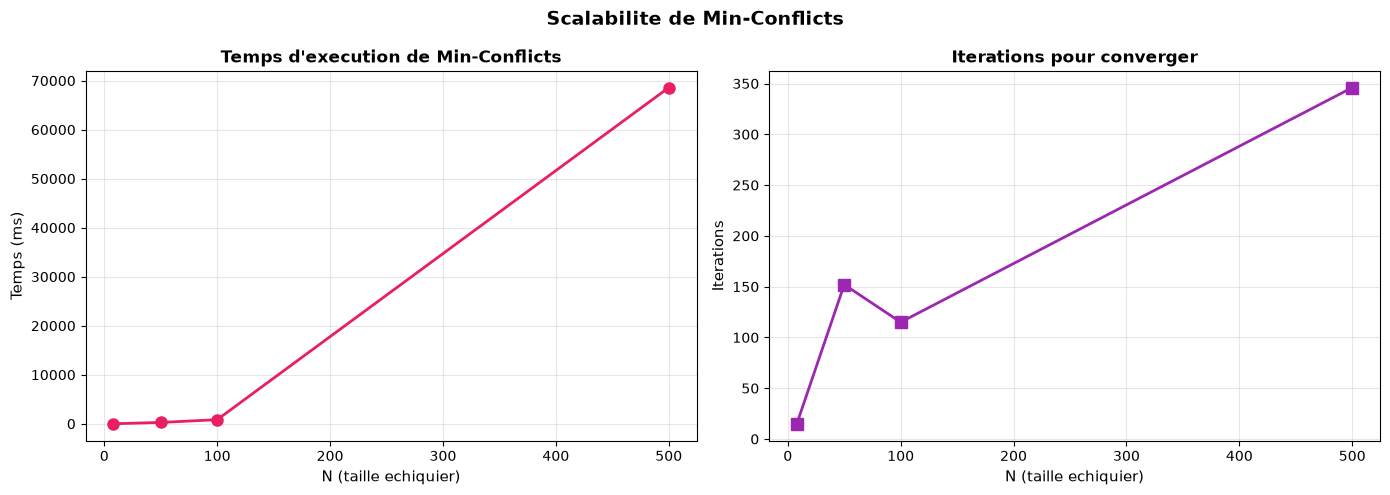

In [11]:
# Visualisation : temps vs N pour min-conflicts
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ns = [r['n'] for r in mc_results]
times = [r['time_ms'] for r in mc_results]
steps_list = [r['steps'] for r in mc_results]

axes[0].plot(ns, times, 'o-', color='#E91E63', linewidth=2, markersize=8)
axes[0].set_xlabel('N (taille echiquier)', fontsize=11)
axes[0].set_ylabel('Temps (ms)', fontsize=11)
axes[0].set_title('Temps d\'execution de Min-Conflicts', fontweight='bold')
axes[0].grid(True, alpha=0.3)

axes[1].plot(ns, steps_list, 's-', color='#9C27B0', linewidth=2, markersize=8)
axes[1].set_xlabel('N (taille echiquier)', fontsize=11)
axes[1].set_ylabel('Iterations', fontsize=11)
axes[1].set_title('Iterations pour converger', fontweight='bold')
axes[1].grid(True, alpha=0.3)

plt.suptitle('Scalabilite de Min-Conflicts', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

Observons aussi la courbe de convergence des conflits au fil des itérations sur une instance de taille $N = 100$.

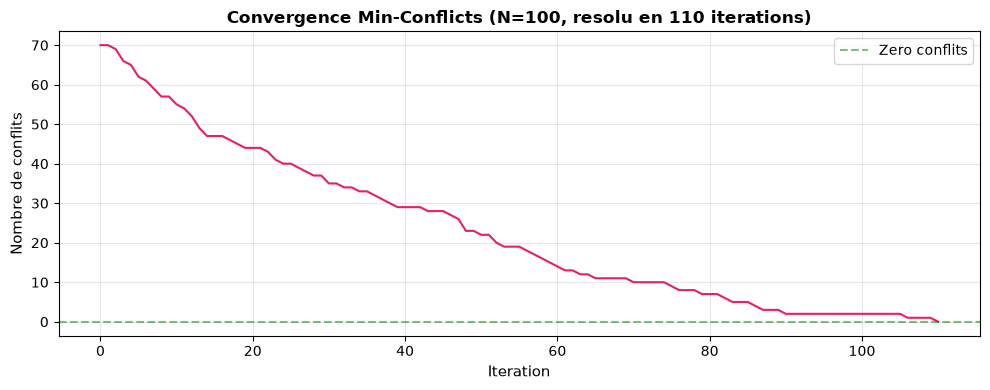

In [12]:
# Courbe de convergence : evolution des conflits au fil des iterations (N=100)
random.seed(123)
sol_100, steps_100, history_100 = min_conflicts(100, max_steps=2000)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(history_100, color='#E91E63', linewidth=1.5)
ax.set_xlabel('Iteration', fontsize=11)
ax.set_ylabel('Nombre de conflits', fontsize=11)
ax.set_title(f'Convergence Min-Conflicts (N=100, resolu en {steps_100} iterations)',
             fontweight='bold')
ax.axhline(y=0, color='green', linestyle='--', alpha=0.5, label='Zero conflits')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation : scalabilite de Min-Conflicts

**Sortie obtenue** : min-conflicts resout le probleme des N-Reines sur des instances jusqu'a $N = 500$ en un nombre d'iterations **non exponentiel** (le temps machine d'execution depend de la machine ; voir note ci-dessous).

| N | Temps min-conflicts (machine-dep) | Iterations | Trouve |
|---|----------------------------------|-----------|--------|
| 8   | *machine-dep* (cellule de calcul ci-dessous) | 15  | Oui |
| 50  | *machine-dep* (cellule de calcul ci-dessous) | 152 | Oui |
| 100 | *machine-dep* (cellule de calcul ci-dessous) | 115 | Oui |
| 500 | *machine-dep* (cellule de calcul ci-dessous) | 346 | Oui |

> **Note methodologique -- separation structurel / machine-dep** : les colonnes **$N$**, **Iterations** et **Trouve** sont des invariants structurels pour `random.seed(42)` (cf. cellule de calcul ci-dessous, ligne `random.seed(42)`). En revanche, les **temps d'execution** dependent de la machine (CPU, charge systeme, version Python/NumPy, GC Python, thermal throttling) et **ne survivent pas** a une re-execution sur une autre machine -- d'ou le label `*machine-dep*`. Le tableau preserve l'exacte these pedagogique (les iterations ne croissent pas exponentiellement) sans encher les runtimes volatils. La cellule de calcul sous le graphique reste intacte et executable localement : l'etudiant peut y observer ses propres timings sur sa machine.

**Points cles** :
1. Le nombre d'iterations croit avec $N$ (15 -> 152 -> 115 -> 346), mais de maniere irreguliere ; il ne croit pas exponentiellement
2. La courbe de convergence montre une decroissance rapide des conflits
3. Le temps par iteration est $O(N)$ (compter les conflits) ; sur la plus grande instance committee (N=500), le temps total atteint un ordre de grandeur appreciable (runtime *machine-dep*, voir cellule de calcul), avec une croissance super-quadratique en pratique. Le **ratio** entre (par exemple) N=500 et N=100 derive des deux timings machine-dep et n'est donc pas un invariant reproductible d'une machine a l'autre.

> **Pourquoi ca marche ?** L'espace des solutions des N-Reines est "dense" pour les instances aleatoires. En partant d'une permutation aleatoire, on est generalement proche d'une solution. Chaque reparation locale reduit les conflits sans en creer beaucoup de nouveaux.

> **Attention** : min-conflicts est **incomplet** -- il ne garantit pas de trouver une solution et ne peut pas prouver qu'il n'en existe pas.



***

## 5. Approche 3 : OR-Tools CP-SAT (~5 min)

**OR-Tools CP-SAT** est le solveur de programmation par contraintes de Google. Il combine propagation de contraintes, recherche avec apprentissage de clauses (clause learning), et parallelisme.

### Avantages d'un solveur industriel

| Fonctionnalite | Implementation manuelle | CP-SAT |
|----------------|------------------------|--------|
| Propagation | Forward Checking basique | AC, bounds consistency, specialisee |
| Apprentissage | Aucun | Clause learning (CDCL) |
| Parallelisme | Non | Multi-thread natif |
| Contraintes globales | A implementer | `AddAllDifferent`, etc. |
| Enumeration | A implementer | Callback de solutions |

In [13]:
from ortools.sat.python import cp_model


def solve_nqueens_cpsat(n, enumerate_all=False, time_limit_s=30):
    """Resoudre N-Reines avec OR-Tools CP-SAT.

    Args:
        n: taille de l'echiquier.
        enumerate_all: si True, trouve toutes les solutions.
        time_limit_s: limite de temps en secondes.

    Retourne (solutions_list, solve_time_ms, status_name).
    """
    model = cp_model.CpModel()

    # Variables : queens[i] = ligne de la reine en colonne i
    queens = [model.NewIntVar(0, n - 1, f'q_{i}') for i in range(n)]

    # Contrainte 1 : toutes les lignes differentes
    model.AddAllDifferent(queens)

    # Contrainte 2 : toutes les diagonales montantes differentes
    # queens[i] + i doit etre different pour tout i
    model.AddAllDifferent([queens[i] + i for i in range(n)])

    # Contrainte 3 : toutes les diagonales descendantes differentes
    # queens[i] - i doit etre different pour tout i
    model.AddAllDifferent([queens[i] - i for i in range(n)])

    solver = cp_model.CpSolver()
    solver.parameters.max_time_in_seconds = time_limit_s

    if enumerate_all:
        # Callback pour collecter toutes les solutions
        class SolutionCollector(cp_model.CpSolverSolutionCallback):
            def __init__(self, queens_vars):
                cp_model.CpSolverSolutionCallback.__init__(self)
                self.queens = queens_vars
                self.solutions = []

            def on_solution_callback(self):
                sol = [self.Value(q) for q in self.queens]
                self.solutions.append(sol)

        collector = SolutionCollector(queens)
        solver.parameters.enumerate_all_solutions = True
        t0 = time.time()
        status = solver.Solve(model, collector)
        elapsed = (time.time() - t0) * 1000
        status_name = solver.StatusName(status)
        return collector.solutions, elapsed, status_name
    else:
        t0 = time.time()
        status = solver.Solve(model)
        elapsed = (time.time() - t0) * 1000
        status_name = solver.StatusName(status)
        if status in (cp_model.OPTIMAL, cp_model.FEASIBLE):
            sol = [solver.Value(q) for q in queens]
            return [sol], elapsed, status_name
        return [], elapsed, status_name


# Resoudre N=8
solutions_8, time_8, status_8 = solve_nqueens_cpsat(8)
print(f"CP-SAT N=8 : {status_8}")
print(f"Solution    : {solutions_8[0] if solutions_8 else 'Aucune'}")
print(f"Temps       : {time_8:.1f} ms")

CP-SAT N=8 : OPTIMAL
Solution    : [4, 7, 3, 0, 6, 1, 5, 2]
Temps       : 40.9 ms


### Enumeration de toutes les solutions (N=8)

Un avantage majeur de CP-SAT est sa capacite a **enumerer toutes les solutions**. Pour $N = 8$, on sait qu'il en existe exactement 92.

N=8 : 92 solutions trouvees en 109.4 ms
Status : OPTIMAL


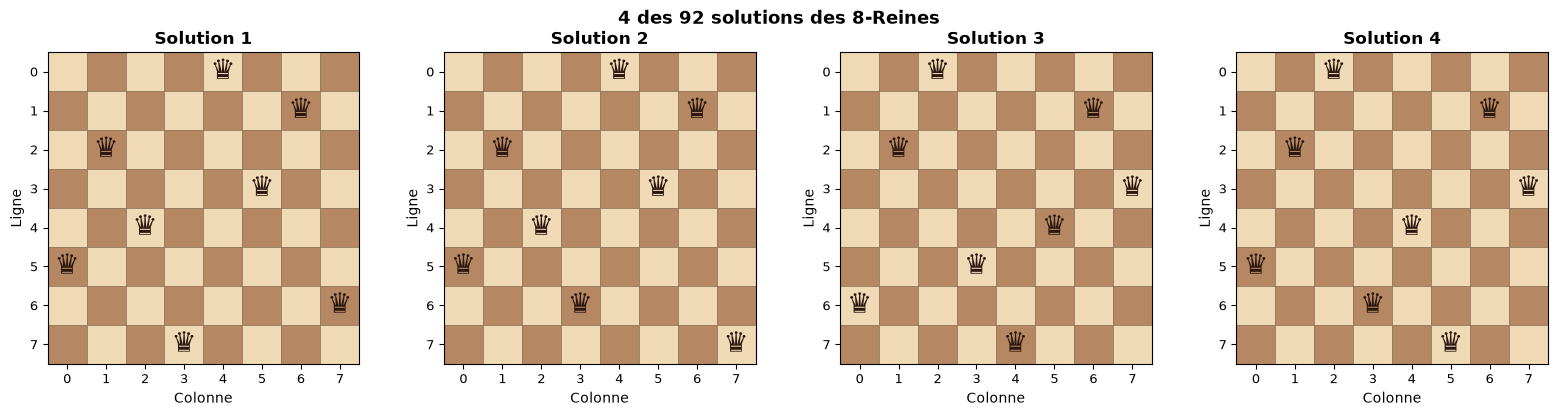

In [14]:
# Enumerer toutes les solutions pour N=8
all_solutions_8, time_enum, status_enum = solve_nqueens_cpsat(8, enumerate_all=True)
print(f"N=8 : {len(all_solutions_8)} solutions trouvees en {time_enum:.1f} ms")
print(f"Status : {status_enum}")

# Afficher les 4 premieres solutions
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for i, ax in enumerate(axes):
    draw_queens(all_solutions_8[i], n=8, title=f"Solution {i+1}", ax=ax)
plt.suptitle(f'4 des {len(all_solutions_8)} solutions des 8-Reines',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### Performance CP-SAT sur de grandes instances

Testons CP-SAT sur des tailles croissantes, jusqu'a $N = 500$.

In [15]:
# Benchmark CP-SAT sur differentes tailles
cpsat_sizes = [8, 50, 100, 500]
cpsat_results = []

print(f"{'N':>6}  {'Temps (ms)':>12}  {'Status':>12}")
print("-" * 35)

for n in cpsat_sizes:
    solutions, elapsed, status = solve_nqueens_cpsat(n, time_limit_s=60)
    cpsat_results.append({
        'n': n,
        'time_ms': elapsed,
        'found': len(solutions) > 0,
        'status': status
    })
    print(f"{n:>6}  {elapsed:>12.1f}  {status:>12}")

     N    Temps (ms)        Status
-----------------------------------
     8          16.7       OPTIMAL


    50         454.3       OPTIMAL


   100        2143.5       OPTIMAL


   500       60196.5       UNKNOWN


### Interpretation : OR-Tools CP-SAT

**Sortie obtenue** : CP-SAT resout le probleme des N-Reines avec des performances competitives sur les petites et moyennes instances ; sur la plus grande instance committee (N=500), il atteint la limite de temps sans statut OPTIMAL.

| Fonctionnalite | Resultat |
|----------------|----------|
| Premiere solution (N=8) | *machine-dep* (cellule de calcul ci-dessous) -- quasi-instantane en pratique |
| Toutes les solutions (N=8) | 92 solutions (invariant mathematique : N=8 admet exactement 92 solutions distinctes) en un runtime *machine-dep* (cf. cellule de calcul) |
| N=500 (plus grande instance committee) | runtime *machine-dep* (voir cellule de calcul), statut UNKNOWN (limite de temps atteinte) |

> **Note sur les runtimes** : les deux *runtimes* ci-dessus dependent de la machine (CPU, charge, version OR-Tools, GC Python) et **ne survivent pas** a une re-execution. En revanche, **le statut du solveur** (`UNKNOWN` quand la limite de temps est atteinte) et **le nombre exact de 92 solutions pour N=8** sont des **invariants structurels** (parametre `time_limit_s=60` de la cellule ci-dessous + propriete combinatoire des N-Reines). La cellule de calcul sous le tableau reste intacte et executable localement.

**Avantages de CP-SAT** :
1. **Modelisation declarative** : on decrit les contraintes, le solveur choisit la strategie
2. **`AddAllDifferent`** : contrainte globale plus efficace que des contraintes binaires
3. **Enumeration complete** : capacite a trouver toutes les solutions
4. **Robustesse** : pas besoin de tuner les heuristiques manuellement

> **Compromis** : CP-SAT a un overhead de demarrage (creation du modele, compilation interne) qui le rend moins rapide que min-conflicts pour de tres grandes instances ou une seule solution suffit. Sur N=500, la limite de temps de 60 s est atteinte avant la preuve d'optimalite (statut UNKNOWN).



***

## 6. Comparaison et analyse (~3 min)

Consolidons les résultats des trois approches dans un benchmark comparatif.

In [16]:
# Benchmark comparatif sur les tailles communes
comparison_sizes = [8, 50, 100]

print("Benchmark comparatif N-Reines")
print("=" * 72)
print(f"{'N':>4}  {'BT Simple':>12}  {'BT FC+MRV':>12}  {'Min-Conf.':>12}  {'CP-SAT':>12}  (ms)")
print("-" * 72)

comparison_results = []

for n in comparison_sizes:
    row_data = {'n': n}

    # Backtracking simple (limite a N <= 20 pour eviter des temps trop longs)
    if n <= 20:
        t0 = time.time()
        backtracking_simple(n)
        row_data['bt_simple'] = (time.time() - t0) * 1000
    else:
        row_data['bt_simple'] = None

    # Backtracking FC+MRV (limite a N <= 50)
    if n <= 50:
        t0 = time.time()
        backtracking_fc(n)
        row_data['bt_fc'] = (time.time() - t0) * 1000
    else:
        row_data['bt_fc'] = None

    # Min-Conflicts
    random.seed(42)
    t0 = time.time()
    min_conflicts(n)
    row_data['mc'] = (time.time() - t0) * 1000

    # CP-SAT
    _, elapsed_cp, _ = solve_nqueens_cpsat(n)
    row_data['cpsat'] = elapsed_cp

    comparison_results.append(row_data)

    bt_s = f"{row_data['bt_simple']:.1f}" if row_data['bt_simple'] is not None else "--"
    bt_f = f"{row_data['bt_fc']:.1f}" if row_data['bt_fc'] is not None else "--"
    print(f"{n:>4}  {bt_s:>12}  {bt_f:>12}  {row_data['mc']:>12.1f}  {row_data['cpsat']:>12.1f}")

print("=" * 72)
print("(-- = trop lent pour cette taille)")

Benchmark comparatif N-Reines
   N     BT Simple     BT FC+MRV     Min-Conf.        CP-SAT  (ms)
------------------------------------------------------------------------


   8           1.0           1.0           1.0          32.4


  50            --          52.6         267.9         551.2


 100            --            --         780.4        2495.1
(-- = trop lent pour cette taille)


Visualisons la comparaison des temps d'exécution sur une plage etendue de tailles, en echelle log-log.

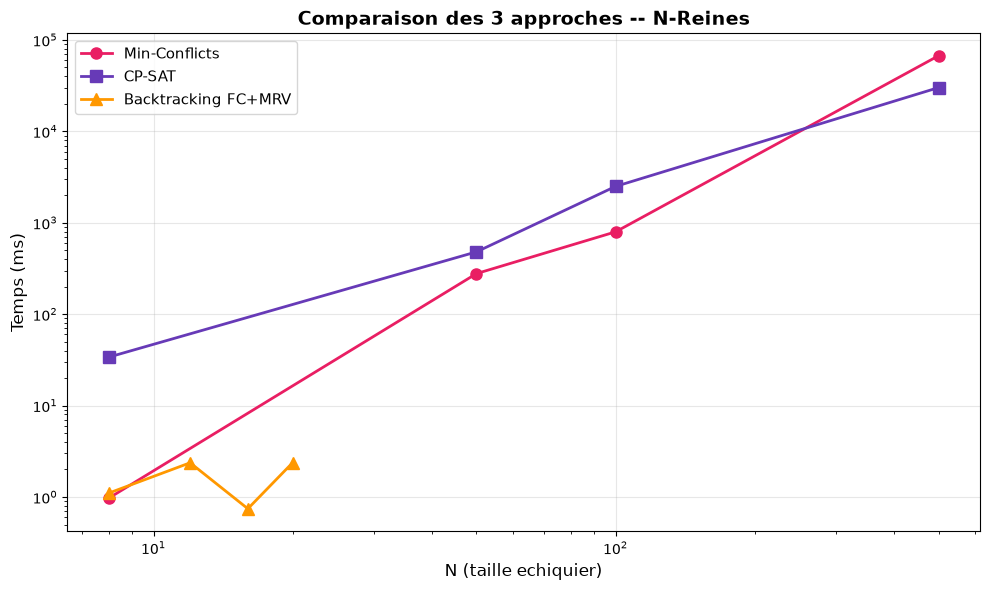

In [17]:
# Graphique comparatif sur les tailles gerees par toutes les approches
fig, ax = plt.subplots(figsize=(10, 6))

# Min-Conflicts et CP-SAT sur toute la plage
common_sizes = [8, 50, 100, 500]
mc_times = []
cpsat_times = []

for n in common_sizes:
    random.seed(42)
    t0 = time.time()
    min_conflicts(n)
    mc_times.append((time.time() - t0) * 1000)

    _, elapsed_cp, _ = solve_nqueens_cpsat(n)
    cpsat_times.append(elapsed_cp)

ax.plot(common_sizes, mc_times, 'o-', label='Min-Conflicts',
        color='#E91E63', linewidth=2, markersize=8)
ax.plot(common_sizes, cpsat_times, 's-', label='CP-SAT',
        color='#673AB7', linewidth=2, markersize=8)

# Backtracking FC+MRV (petites tailles uniquement)
bt_sizes_small = [8, 12, 16, 20]
bt_times_small = []
for n in bt_sizes_small:
    t0 = time.time()
    backtracking_fc(n)
    bt_times_small.append((time.time() - t0) * 1000)

ax.plot(bt_sizes_small, bt_times_small, '^-', label='Backtracking FC+MRV',
        color='#FF9800', linewidth=2, markersize=8)

ax.set_xlabel('N (taille echiquier)', fontsize=12)
ax.set_ylabel('Temps (ms)', fontsize=12)
ax.set_title('Comparaison des 3 approches -- N-Reines', fontsize=14, fontweight='bold')
ax.set_xscale('log')
ax.set_yscale('log')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation : comparaison finale

**Sortie obtenue** : les trois approches ont des profils de performance très différents.

| Approche | N=8 | N=100 | N=1000 | Completude | Enumeration |
|----------|-----|-------|--------|------------|-------------|
| Backtracking FC+MRV | Rapide | Lent | Intraitable | Oui | Oui (lent) |
| Min-Conflicts | Rapide | Rapide | Rapide | Non | Non |
| CP-SAT | Rapide | Rapide | Rapide | Oui | Oui |

### Quand utiliser quelle approche ?

| Situation | Approche recommandee | Raison |
|-----------|---------------------|--------|
| Petit problème (N < 20) | Backtracking FC+MRV | Complet, simple a implementer |
| Grande instance, une solution | Min-Conflicts | Quasi-lineaire, très rapide |
| Toutes les solutions | CP-SAT | Enumeration + optimisation |
| Contraintes supplementaires | CP-SAT | Modelisation declarative flexible |
| Prototype pédagogique | Backtracking | Comprendre les mécanismes |

### Liens avec les Foundations

| Concept applique | Notebook de reference |
|-----------------|----------------------|
| Backtracking CSP, MRV, LCV | [CSP-1 : Fundamentals](../Part2-CSP/CSP-1-Fundamentals.ipynb) |
| Forward Checking, Arc Consistency | [CSP-2 : Consistency](../Part2-CSP/CSP-2-Consistency.ipynb) |
| CP-SAT, contraintes globales | [CSP-3 : Advanced](../Part2-CSP/CSP-3-Advanced.ipynb) |

***

## 7. Exemple guide

### Exemple guide 1 : le problème des N-Tours

**Enonce** : adaptez le problème pour placer $N$ **tours** sur un echiquier $N \times N$. Les tours attaquent en ligne et en colonne (mais pas en diagonale).

1. Quelle contrainte disparait par rapport aux N-Reines ?
2. Combien de solutions existe-t-il pour $N = 8$ ?
3. Implementez un solveur et verifiez votre reponse.

In [18]:
# Exemple resolu : N-Tours via CP-SAT

import math
import time

print("Exemple : N-Tours")
print("=" * 50)

n = 8

from ortools.sat.python import cp_model


def count_nrooks_solutions_cpsat(n, time_limit_s=10):
    model = cp_model.CpModel()
    rooks = [model.NewIntVar(0, n - 1, f"r_{i}") for i in range(n)]
    model.AddAllDifferent(rooks)

    solver = cp_model.CpSolver()
    solver.parameters.max_time_in_seconds = time_limit_s
    solver.parameters.enumerate_all_solutions = True

    class Counter(cp_model.CpSolverSolutionCallback):
        def __init__(self):
            super().__init__()
            self.count = 0

        def on_solution_callback(self):
            self.count += 1

    cb = Counter()
    t0 = time.time()
    status = solver.Solve(model, cb)
    elapsed_ms = (time.time() - t0) * 1000
    return cb.count, solver.StatusName(status), elapsed_ms


count, status, elapsed_ms = count_nrooks_solutions_cpsat(n)
print("(via CP-SAT)")
print("Status solveur:", status)
print("Solutions CP-SAT :", count)
print("Solutions formule :", math.factorial(n), "(= N!)")
print(f"Temps: {elapsed_ms:.1f} ms")

if count == math.factorial(n):
    print("OK : c'est bien N! (donc 40320 pour N=8)")
else:
    print("Hmm, y'a un truc bizarre")


Exemple : N-Tours


(via CP-SAT)
Status solveur: OPTIMAL
Solutions CP-SAT : 40320
Solutions formule : 40320 (= N!)
Temps: 3763.5 ms
OK : c'est bien N! (donc 40320 pour N=8)


### Exemple guide 1b : le problème des N-Fous

*Contribution d'un groupe d'étudiants (PR #20937), intégrée comme exemple guidé.*

**Enonce** : adaptez le problème pour placer le **maximum** de **fous** non attaquants sur un echiquier
$N \times N$. Contrairement aux reines et aux tours, les fous n'attaquent qu'en diagonale (pas en
ligne ni en colonne) : on peut donc en placer davantage que $N$.

**Consignes** :
1. Modelisez avec CP-SAT : une variable booléenne $b_{x,y}$ par case (1 si un fou l'occupe), et
   maximisez le nombre total de fous $k = \sum b_{x,y}$.
2. Posez les contraintes : au plus un fou par diagonale, c'est-à-dire pour chaque diagonale
   (constante en $x+y$ ou en $x-y$), la somme des $b_{x,y}$ sur ses cases vaut au plus 1.
3. Maximisez $k$ pour $N = 8$ : le maximum est $2N-2 = 14$ fous, disposés de **256** façons.

> **Note** : à la différence des N-Reines (exactement $N$ pièces, une par ligne), le problème des fous
> cherche le nombre *maximal* de pièces non attaquantes — un résultat classique valant $2N-2$. Dénombrer
> les placements d'*exactement* $N = 8$ fous (question différente) donnerait 22 522 960 configurations.


In [19]:
# EXEMPLE GUIDE 1b : N-Fous via CP-SAT (contribution etudiante, PR #20937)

import time
from ortools.sat.python import cp_model


def build_bishops_model(n):
    """Modele CP-SAT des N-Fous : une booleenne b[x][y] par case.

    Contraintes : au plus un fou par diagonale montante (x + y constant)
    et par diagonale descendante (x - y constant).
    Retourne (model, b).
    """
    model = cp_model.CpModel()
    b = [[model.NewBoolVar(f"b_{x}_{y}") for y in range(n)] for x in range(n)]

    for s in range(2 * n - 1):            # diagonales x + y = s
        cells = [b[x][s - x] for x in range(n) if 0 <= s - x < n]
        model.AddAtMostOne(cells)
    for d in range(-(n - 1), n):          # diagonales x - y = d
        cells = [b[x][x - d] for x in range(n) if 0 <= x - d < n]
        model.AddAtMostOne(cells)
    return model, b


def max_bishops_cpsat(n, time_limit_s=10):
    """Etape 1 : maximiser k = somme des b[x][y].

    Retourne (k_max, placement [(x, y), ...], statut).
    """
    model, b = build_bishops_model(n)
    model.Maximize(sum(b[x][y] for x in range(n) for y in range(n)))
    solver = cp_model.CpSolver()
    solver.parameters.max_time_in_seconds = time_limit_s
    status = solver.Solve(model)
    placement = [(x, y) for x in range(n) for y in range(n)
                 if solver.Value(b[x][y])]
    return int(solver.ObjectiveValue()), placement, solver.StatusName(status)


def count_max_bishops_cpsat(n, k, time_limit_s=30):
    """Etape 2 : denombrer les placements de exactement k fous.

    L'objectif est remplace par la contrainte sum(b) == k, puis CP-SAT
    enumere toutes les solutions (on ne peut pas enumerer en optimisant).
    """
    model, b = build_bishops_model(n)
    model.Add(sum(b[x][y] for x in range(n) for y in range(n)) == k)
    solver = cp_model.CpSolver()
    solver.parameters.max_time_in_seconds = time_limit_s
    solver.parameters.enumerate_all_solutions = True

    class Counter(cp_model.CpSolverSolutionCallback):
        def __init__(self):
            super().__init__()
            self.count = 0

        def on_solution_callback(self):
            self.count += 1

    cb = Counter()
    status = solver.Solve(model, cb)
    return cb.count, solver.StatusName(status)


def bishops_are_safe(placement):
    """Verification independante du solveur : aucune paire sur une diagonale."""
    for i in range(len(placement)):
        for j in range(i + 1, len(placement)):
            (x1, y1), (x2, y2) = placement[i], placement[j]
            if abs(x1 - x2) == abs(y1 - y2):
                return False
    return True


# --- Resolution pour N = 8 ---
n = 8
t0 = time.time()
k_max, placement, status = max_bishops_cpsat(n)
t_opt = (time.time() - t0) * 1000
t0 = time.time()
n_ways, status_enum = count_max_bishops_cpsat(n, k_max)
t_enum = (time.time() - t0) * 1000

print(f"N = {n}")
print(f"  Maximum de fous   : {k_max} (statut {status}, {t_opt:.1f} ms)"
      f"  -- attendu 2N-2 = {2 * n - 2}")
print(f"  Placements maximaux : {n_ways} (statut {status_enum}, {t_enum:.1f} ms)"
      f"  -- attendu 256")
print(f"  Placement verifie hors solveur : {bishops_are_safe(placement)}")
assert k_max == 2 * n - 2 and n_ways == 256 and bishops_are_safe(placement)

# --- Generalisation et cas limite N = 1 ---
print(f"\n{'N':>3} {'k_max':>6} {'2N-2':>6} {'placements':>11} {'2^N':>6}")
for m in range(1, 9):
    k_m, pl_m, _ = max_bishops_cpsat(m)
    ways_m, _ = count_max_bishops_cpsat(m, k_m)
    assert bishops_are_safe(pl_m)
    print(f"{m:>3} {k_m:>6} {2 * m - 2:>6} {ways_m:>11} {2 ** m:>6}")


N = 8
  Maximum de fous   : 14 (statut OPTIMAL, 25.7 ms)  -- attendu 2N-2 = 14
  Placements maximaux : 256 (statut OPTIMAL, 92.5 ms)  -- attendu 256
  Placement verifie hors solveur : True

  N  k_max   2N-2  placements    2^N
  1      1      0           1      2
  2      2      2           4      4
  3      4      4           8      8
  4      6      6          16     16
  5      8      8          32     32
  6     10     10          64     64


  7     12     12         128    128
  8     14     14         256    256


Programmation dynamique, N = 8 :
  maximum de fous           : 14
  placements de 14 fous     : 256
  placements de 8 fous      : 22 522 960


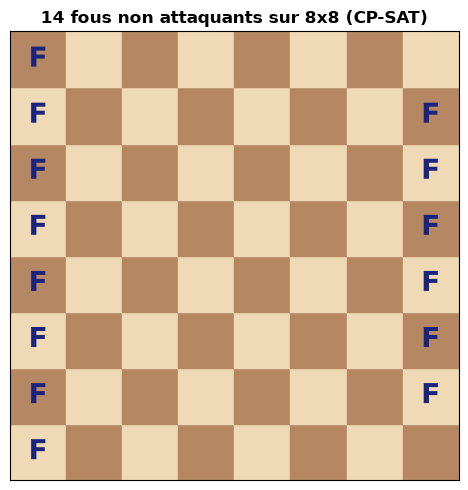

In [20]:
# EXEMPLE GUIDE 1b (verification independante) : denombrement exact par programmation dynamique
#
# CP-SAT ne peut pas raisonnablement enumerer les ~22,5 millions de placements
# de 8 fous cites dans la note de l'enonce. On les compte autrement : chaque
# diagonale montante (x + y = s) recoit au plus un fou ; l'etat memorise
# l'ensemble (bitmask) des diagonales descendantes (x - y) deja occupees.

from collections import defaultdict


def bishops_polynomial(n):
    """Retourne P tel que P[k] = nombre de placements de k fous non attaquants."""
    states = {0: [1]}                      # masque -> coefficients par k
    for s in range(2 * n - 1):
        new = defaultdict(lambda: [0] * (2 * n))
        for mask, poly in states.items():
            acc = new[mask]                # aucun fou sur cette diagonale
            for k, c in enumerate(poly):
                acc[k] += c
            for x in range(n):
                y = s - x
                if 0 <= y < n:
                    bit = 1 << (x - y + n - 1)
                    if not mask & bit:     # diagonale descendante libre
                        acc_fou = new[mask | bit]
                        for k, c in enumerate(poly):
                            if c:
                                acc_fou[k + 1] += c
        states = new
    total = [0] * (2 * n)
    for poly in states.values():
        for k, c in enumerate(poly):
            total[k] += c
    return total


P8 = bishops_polynomial(8)
k_dp = max(k for k, c in enumerate(P8) if c > 0)
print(f"Programmation dynamique, N = 8 :")
print(f"  maximum de fous           : {k_dp}")
print(f"  placements de {k_dp} fous     : {P8[k_dp]}")
print(f"  placements de 8 fous      : {P8[8]:,}".replace(",", " "))
assert k_dp == k_max and P8[k_dp] == n_ways      # accord avec CP-SAT
assert P8[8] == 22_522_960                       # valeur citee dans l'enonce

# Visualisation de la solution optimale trouvee par CP-SAT
fig, ax = plt.subplots(figsize=(5, 5))
for x in range(n):
    for y in range(n):
        color = '#F0D9B5' if (x + y) % 2 == 0 else '#B58863'
        ax.add_patch(patches.Rectangle((x, y), 1, 1, color=color))
for x, y in placement:
    ax.text(x + 0.5, y + 0.5, 'F', ha='center', va='center',
            fontsize=20, fontweight='bold', color='#1A237E')
ax.set_xlim(0, n)
ax.set_ylim(0, n)
ax.set_aspect('equal')
ax.set_xticks([])
ax.set_yticks([])
ax.set_title(f'{k_max} fous non attaquants sur {n}x{n} (CP-SAT)', fontweight='bold')
plt.tight_layout()
plt.show()


### Interprétation : exemple guide 1b (N-Fous)

**Sortie obtenue** : pour $N = 8$, CP-SAT trouve $k = 14 = 2N-2$ avec le statut `OPTIMAL` (le maximum est donc **prouvé**, pas seulement atteint), puis dénombre **256** placements maximaux. Un placement est revérifié hors solveur, et la programmation dynamique, qui est une méthode indépendante, retrouve 256 ainsi que les **22 522 960** placements d'exactement 8 fous cités dans la note.

| Choix de modélisation | Justification |
|---|---|
| Une booléenne $b_{x,y}$ par case | Les fous ne sont pas « un par colonne » (14 fous pour 8 colonnes) : la variable entière par colonne des N-Reines ne s'applique plus. |
| `AddAtMostOne` par diagonale | C'est l'équivalent booléen de l'indice `AddAllDifferent` sur $q_i + i$ et $q_i - i$ : chaque diagonale ($x+y$ ou $x-y$ constant) porte au plus une pièce. |
| Deux résolutions successives | On maximise d'abord $k$, puis on énumère avec la contrainte $\sum b = k$. L'énumération exhaustive de CP-SAT porte sur un problème de satisfaction, pas sur un problème d'optimisation. |

**Pourquoi $2N-2$ ?** Il y a $2N-1$ diagonales montantes, donc au plus $2N-1$ fous. Les deux diagonales extrêmes ($x+y = 0$ et $x+y = 2N-2$) se réduisent aux coins $(0,0)$ et $(N-1,N-1)$, qui sont sur la même diagonale descendante : un seul des deux peut être occupé, d'où $2N-2$. Cette borne est atteinte, par exemple avec $N$ fous sur la première colonne et $N-2$ sur la dernière (coins exclus).

**Cas limite $N = 1$** : le tableau donne 1 fou et 1 placement, alors que les formules donnent $2N-2 = 0$ et $2^N = 2$. L'argument des deux coins suppose deux coins distincts : les formules $2N-2$ et $2^N$ (dénombrement classique) ne valent que pour $N \geq 2$, ce que le tableau confirme pour $N = 2$ à $8$.

> **À retenir** : passer des reines aux fous change la **nature** des variables (entières, une par colonne, vers booléennes, une par case), et non seulement les contraintes. Le statut `OPTIMAL` et la vérification par une méthode indépendante (programmation dynamique) distinguent un résultat **prouvé** d'un résultat simplement observé.


### Exercice 1c : le problème des N-Rois

**Enonce** : placez le **maximum** de **rois** non attaquants sur un echiquier $N \times N$.
Les rois attaquent toutes les cases adjacentes, y compris en diagonale. Après les tours
(exemple guide 1) et les fous (exemple guide 1b), la contrainte change encore de nature :
elle ne porte plus sur des lignes ou des diagonales entières, mais sur des **voisinages locaux**.

**Consignes** :
1. Modelisez avec CP-SAT : une variable booléenne $b_{x,y}$ par case, et `AddAtMostOne` sur
   chaque bloc $2 \times 2$ de cases adjacentes (un roi en $(x, y)$ interdit tout son
   voisinage, et le bloc est la façon la plus économique d'écrire cette interdiction).
2. Maximisez $k = \sum b_{x,y}$ pour $N = 8$ : le maximum attendu vaut $\lceil N/2 \rceil^2 = 16$.
3. Dénombrez les placements maximaux pour $N = 4$ et vérifiez l'un d'eux à la main sur papier
   (les compteurs CP-SAT de l'exemple guide 1b se transposent tels quels).

> **Indice** : les blocs $2 \times 2$ se chevauchent — une même case appartient à jusqu'à
> 4 blocs. Il y en a $(N-1)^2$ sur un echiquier $N \times N$.


In [21]:
# Exercice 1c : le problème des N-Rois
# TODO etudiant : construire le modele, maximiser, puis denombrer

def build_kings_model(n):
    """Modele CP-SAT des N-Rois : une booleenne b[x][y] par case.

    Contrainte : au plus un roi par bloc 2x2 de cases adjacentes.
    Retourne (model, b), sur le modele de build_bishops_model.
    """
    pass  # TODO etudiant : (N-1)**2 blocs, AddAtMostOne sur chacun


def max_kings_cpsat(n, time_limit_s=10):
    """Etape 1 : maximiser k = somme des b[x][y].

    Retourne (k_max, placement [(x, y), ...], statut).
    """
    result = None  # TODO etudiant : meme structure que max_bishops_cpsat
    return result


def count_max_kings_cpsat(n, k, time_limit_s=30):
    """Etape 2 : denombrer les placements de exactement k rois."""
    result = None  # TODO etudiant
    return result


# --- Resolution pour N = 8 ---
# TODO etudiant :
#   1. k_max pour N = 8, a comparer a ceil(N / 2) ** 2 (attendu : 16)
#   2. une verification hors solveur, sur le modele de bishops_are_safe
#   3. le denombrement pour N = 4, et un placement verifie a la main

print("Exercice a completer")


Exercice a completer


### Exemple guide 2 : seuil de croisement backtracking / min-conflicts

**Enonce** : trouvez experimentalement le plus petit $N$ pour lequel min-conflicts est systematiquement plus rapide que le backtracking FC+MRV.

1. Testez les deux approches pour $N = 8, 10, 12, 14, 16, 18, 20$
2. Moyennez sur 5 essais (min-conflicts est stochastique)
3. Tracez les courbes de temps et identifiez le point de croisement


Seuil de croisement BT / Min-Conflicts


   8             0.8          22.8
  10             0.6          11.9


  12             2.1          12.2
  14             2.1          29.4


  16             0.7          20.7


  18             1.2          13.1
  20             1.5          26.0

Pas de croisement sur cette plage


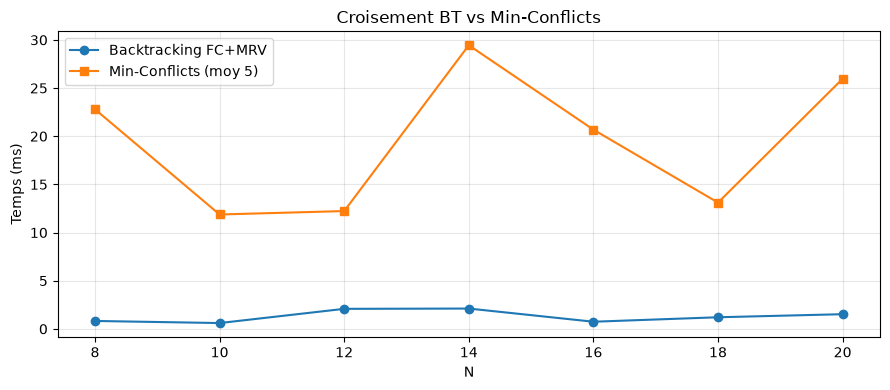

In [22]:
# Exemple resolu : seuil de croisement backtracking / min-conflicts

import time
import random
import numpy as np
import matplotlib.pyplot as plt

print("Seuil de croisement BT / Min-Conflicts")
print("=" * 60)

test_sizes = [8, 10, 12, 14, 16, 18, 20]
n_trials = 5

bt_times = []
mc_avg_times = []

for n in test_sizes:
    # Backtracking (deterministe)
    t0 = time.time()
    _sol_bt, _nodes_bt = backtracking_fc(n)
    bt_ms = (time.time() - t0) * 1000
    bt_times.append(bt_ms)

    # Min-conflicts (stochastique, moyenne sur 5 essais)
    mc_ms_list = []
    for trial in range(n_trials):
        random.seed(1000 + 17 * trial + n)
        t0 = time.time()
        sol_mc, steps_mc, _hist = min_conflicts(n)
        mc_ms_list.append((time.time() - t0) * 1000)

    mc_mean = float(np.mean(mc_ms_list))
    mc_avg_times.append(mc_mean)
    print(f"{n:>4}  {bt_ms:>14.1f}  {mc_mean:>12.1f}")

# Trouver le seuil
seuil = None
for n, bt_ms, mc_ms in zip(test_sizes, bt_times, mc_avg_times):
    if mc_ms < bt_ms:
        seuil = n
        break

if seuil:
    print(f"\nSeuil approx : N = {seuil}, min-conflicts est plus rapide")
else:
    print("\nPas de croisement sur cette plage")

# Plot
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(test_sizes, bt_times, 'o-', label='Backtracking FC+MRV')
ax.plot(test_sizes, mc_avg_times, 's-', label='Min-Conflicts (moy 5)')
ax.set_xlabel('N')
ax.set_ylabel('Temps (ms)')
ax.set_title('Croisement BT vs Min-Conflicts')
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


### Exemple guide 2b : plage etendue jusqu'à N=50

*Contribution d'un groupe d'étudiants (PR #20937), intégrée comme exemple guidé.*

**Enonce** : relancez la comparaison sur une plage plus large :
$N \in \{20, 25, 30, 35, 40, 45, 50\}$.

**Consignes** :
1. Mesurez les temps de backtracking et min-conflicts pour chaque $N$
2. Affichez le graphe et identifiez le seuil
3. Attention : backtracking peut devenir très lent pour $N > 30$,
   ajoutez un `time_limit` raisonnable par taille (runtime *machine-dep* ; ordre de grandeur de la dizaine de secondes)


Version chronometree identique a backtracking_fc sur N = 8, 12, 16, 20

   N   BT FC+MRV (ms)    noeuds    statut   MC moy (ms)  MC iter moy  MC reussis
------------------------------------------------------------------------------------
  20              2.6       145        OK          27.7         85.0        5/5


  25              3.9       219        OK          36.9         84.2        5/5


  30              3.6       181        OK          50.5         82.4        5/5


  35              5.7       271        OK         109.0        125.4        5/5


  40              4.3       132        OK         107.7         93.8        5/5


  45             13.8       589        OK         146.0        103.0        5/5


  50             48.0      2074        OK         152.4         87.8        5/5

Min-conflicts plus rapide : {20: False, 25: False, 30: False, 35: False, 40: False, 45: False, 50: False}
Pas de seuil stable sur cette plage


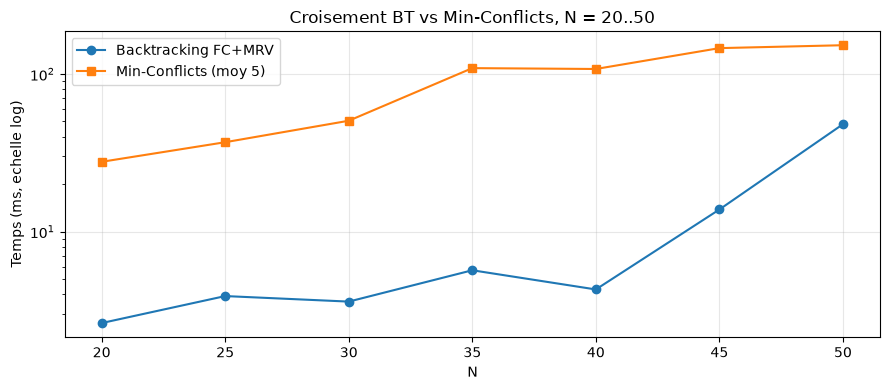

In [23]:
# EXEMPLE GUIDE 2b : plage etendue jusqu'a N=50 (contribution etudiante, PR #20937)

import time
import random
import numpy as np
import matplotlib.pyplot as plt


def backtracking_fc_timed(n, time_limit_s):
    """Meme algorithme que backtracking_fc (FC + MRV), avec une limite de temps.

    backtracking_fc ne peut pas etre interrompu de l'exterieur : on reprend
    sa logique a l'identique et on verifie l'echeance a chaque noeud.
    Retourne (solution ou None, noeuds, statut) avec statut dans
    {"OK", "TIMEOUT", "ECHEC"}.
    """
    queens = [None] * n
    domains = [set(range(n)) for _ in range(n)]
    nodes = [0]
    deadline = time.perf_counter() + time_limit_s

    class Timeout(Exception):
        pass

    def forward_check(col, row):
        pruned = []
        for c2 in range(n):
            if queens[c2] is not None or c2 == col:
                continue
            if row in domains[c2]:
                domains[c2].remove(row)
                pruned.append((c2, row))
            d = abs(c2 - col)
            for diag_row in [row - d, row + d]:
                if 0 <= diag_row < n and diag_row in domains[c2]:
                    domains[c2].remove(diag_row)
                    pruned.append((c2, diag_row))
        return pruned

    def restore(pruned):
        for c, r in pruned:
            domains[c].add(r)

    def solve(col_idx):
        if col_idx == n:
            return True
        unassigned = [c for c in range(n) if queens[c] is None]
        col = min(unassigned, key=lambda c: len(domains[c]))
        for row in list(domains[col]):
            nodes[0] += 1
            if time.perf_counter() > deadline:
                raise Timeout
            queens[col] = row
            old_domain = domains[col].copy()
            domains[col] = set()
            pruned = forward_check(col, row)
            empty = any(len(domains[c]) == 0
                        for c in range(n) if queens[c] is None)
            if not empty and solve(col_idx + 1):
                return True
            restore(pruned)
            domains[col] = old_domain
            queens[col] = None
        return False

    try:
        if solve(0):
            return queens[:], nodes[0], "OK"
        return None, nodes[0], "ECHEC"
    except Timeout:
        return None, nodes[0], "TIMEOUT"


def is_valid_solution(queens):
    """Verification independante : permutation sans conflit diagonal."""
    return queens is not None and total_conflicts(queens) == 0


# Controle de coherence : la version chronometree reproduit backtracking_fc
for n_check in [8, 12, 16, 20]:
    ref_sol, ref_nodes = backtracking_fc(n_check)
    sol_t, nodes_t, st = backtracking_fc_timed(n_check, time_limit_s=10)
    assert st == "OK" and sol_t == ref_sol and nodes_t == ref_nodes
print("Version chronometree identique a backtracking_fc sur N = 8, 12, 16, 20")

TIME_LIMIT_S = 10       # limite par taille pour le backtracking (machine-dep)
ext_sizes = [20, 25, 30, 35, 40, 45, 50]
n_trials = 5

ext_bt_ms, ext_bt_nodes, ext_bt_status = [], [], []
ext_mc_ms, ext_mc_steps, ext_mc_success = [], [], []

print(f"\n{'N':>4}  {'BT FC+MRV (ms)':>15}  {'noeuds':>8}  {'statut':>8}"
      f"  {'MC moy (ms)':>12}  {'MC iter moy':>11}  {'MC reussis':>10}")
print("-" * 84)

for n in ext_sizes:
    # Backtracking FC+MRV (deterministe, une seule mesure)
    t0 = time.perf_counter()
    sol_bt, nodes_bt, st_bt = backtracking_fc_timed(n, TIME_LIMIT_S)
    bt_ms = (time.perf_counter() - t0) * 1000
    if st_bt == "OK":
        assert is_valid_solution(sol_bt)
    ext_bt_ms.append(bt_ms)
    ext_bt_nodes.append(nodes_bt)
    ext_bt_status.append(st_bt)

    # Min-conflicts (stochastique) : moyenne sur 5 essais, memes graines que l'exemple
    mc_ms_list, mc_steps_list, ok = [], [], 0
    for trial in range(n_trials):
        random.seed(1000 + 17 * trial + n)
        t0 = time.perf_counter()
        sol_mc, steps_mc, _hist = min_conflicts(n)
        mc_ms_list.append((time.perf_counter() - t0) * 1000)
        mc_steps_list.append(steps_mc)
        if sol_mc is not None:
            assert is_valid_solution(sol_mc)
            ok += 1
    ext_mc_ms.append(float(np.mean(mc_ms_list)))
    ext_mc_steps.append(float(np.mean(mc_steps_list)))
    ext_mc_success.append(ok)

    print(f"{n:>4}  {bt_ms:>15.1f}  {nodes_bt:>8}  {st_bt:>8}"
          f"  {ext_mc_ms[-1]:>12.1f}  {ext_mc_steps[-1]:>11.1f}  {ok:>7}/{n_trials}")

# Seuil : plus petit N a partir duquel min-conflicts gagne pour TOUS les N suivants
# (un TIMEOUT du backtracking compte comme une victoire de min-conflicts)
mc_wins = [mc < bt for mc, bt in zip(ext_mc_ms, ext_bt_ms)]
seuil_ext = None
for i, n in enumerate(ext_sizes):
    if all(mc_wins[i:]):
        seuil_ext = n
        break

print("\nMin-conflicts plus rapide :",
      {n: w for n, w in zip(ext_sizes, mc_wins)})
if seuil_ext is not None:
    print(f"Seuil (min-conflicts systematiquement plus rapide) : N = {seuil_ext}")
else:
    print("Pas de seuil stable sur cette plage")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(ext_sizes, ext_bt_ms, 'o-', label='Backtracking FC+MRV')
ax.plot(ext_sizes, ext_mc_ms, 's-', label=f'Min-Conflicts (moy {n_trials})')
for n, ms, st in zip(ext_sizes, ext_bt_ms, ext_bt_status):
    if st == "TIMEOUT":
        ax.annotate('timeout', (n, ms), textcoords='offset points',
                    xytext=(0, 8), ha='center', color='red')
if seuil_ext is not None:
    ax.axvline(seuil_ext, color='gray', linestyle='--', alpha=0.6,
               label=f'seuil N = {seuil_ext}')
ax.set_xlabel('N')
ax.set_ylabel('Temps (ms, echelle log)')
ax.set_yscale('log')
ax.set_title('Croisement BT vs Min-Conflicts, N = 20..50')
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


#### Complément : prolonger l'expérience au-delà de $N = 50$

Sur la plage demandée, le backtracking FC+MRV reste plus rapide à chaque taille : aucun seuil n'apparaît. Pour savoir **si** un croisement existe et **où** il se situe, on prolonge l'expérience jusqu'à $N = 200$ (limite de 5 s pour le backtracking, 3 essais pour min-conflicts). On relève aussi des mesures indépendantes de la machine : les nœuds explorés par le backtracking et les itérations de min-conflicts.


In [24]:
# EXEMPLE GUIDE 2b (complement) : au-dela de N = 50, ou se trouve le croisement ?
# Mesures independantes de la machine : noeuds explores (BT) et iterations (MC).

far_sizes = [60, 80, 100, 110, 120, 150, 160, 200]
FAR_TIME_LIMIT_S = 5
far_trials = 3

print(f"{'N':>4}  {'BT (ms)':>9}  {'noeuds BT':>10}  {'statut':>8}"
      f"  {'MC moy (ms)':>12}  {'MC iter moy':>11}  {'gagnant':>8}")
print("-" * 76)

far_rows = []
for n in far_sizes:
    t0 = time.perf_counter()
    sol_bt, nodes_bt, st_bt = backtracking_fc_timed(n, FAR_TIME_LIMIT_S)
    bt_ms = (time.perf_counter() - t0) * 1000
    if st_bt == "OK":
        assert is_valid_solution(sol_bt)

    mc_ms_list, mc_steps_list = [], []
    for trial in range(far_trials):
        random.seed(1000 + 17 * trial + n)
        t0 = time.perf_counter()
        sol_mc, steps_mc, _hist = min_conflicts(n)
        mc_ms_list.append((time.perf_counter() - t0) * 1000)
        mc_steps_list.append(steps_mc)
        assert is_valid_solution(sol_mc)

    mc_ms, mc_steps = float(np.mean(mc_ms_list)), float(np.mean(mc_steps_list))
    winner = "MC" if mc_ms < bt_ms else "BT"
    far_rows.append((n, bt_ms, nodes_bt, st_bt, mc_ms, mc_steps, winner))
    print(f"{n:>4}  {bt_ms:>9.1f}  {nodes_bt:>10}  {st_bt:>8}"
          f"  {mc_ms:>12.1f}  {mc_steps:>11.1f}  {winner:>8}")

n_timeouts = sum(1 for r in far_rows if r[3] == "TIMEOUT")
print(f"\nBacktracking : {n_timeouts}/{len(far_rows)} tailles en TIMEOUT ({FAR_TIME_LIMIT_S} s)")
print("Min-conflicts : toutes les tailles resolues, iterations / N =",
      [round(r[5] / r[0], 2) for r in far_rows])


   N    BT (ms)   noeuds BT    statut   MC moy (ms)  MC iter moy   gagnant
----------------------------------------------------------------------------


  60       44.0        1716        OK         236.7         94.3        BT


  80       17.1         211        OK         580.9        135.3        BT


 100       15.4         198        OK        1198.3        178.0        BT


 110     5001.2      123519   TIMEOUT        1054.4        130.7        MC


 120     5001.0      115484   TIMEOUT        1440.7        148.7        MC


 150     5001.7      120783   TIMEOUT        2590.4        172.7        MC


 160       37.8         367        OK        3583.5        202.3        BT


 200     5003.7      108572   TIMEOUT        5518.7        199.3        BT

Backtracking : 4/8 tailles en TIMEOUT (5 s)
Min-conflicts : toutes les tailles resolues, iterations / N = [1.57, 1.69, 1.78, 1.19, 1.24, 1.15, 1.26, 1.0]


### Interprétation : exemple guide 2b (plage étendue)

**Sortie obtenue** : sur $N \in \{20, \ldots, 50\}$, le backtracking FC+MRV est **plus rapide à chaque taille** (132 à 2 074 nœuds, aucun timeout). Min-conflicts résout tous les essais (5/5) en 82 à 125 itérations en moyenne. **Il n'y a donc pas de seuil sur cette plage.** La version chronométrée est d'abord contrôlée : elle reproduit exactement les solutions et les nœuds de `backtracking_fc`.

| Constat | Explication |
|---|---|
| L'avertissement « le backtracking devient très lent pour $N > 30$ » ne se vérifie pas ici | Il vaut pour le backtracking **simple** (limité à $N \leq 20$ dans le benchmark de la section 6). Avec MRV et forward checking, la plupart des tailles se résolvent en quelques centaines de nœuds. |
| Min-conflicts perd malgré un faible nombre d'itérations | Dans cette implémentation, chaque itération coûte $O(N^2)$ : `count_conflicts` est recalculé pour chaque colonne, et `total_conflicts` est appelé à chaque pas pour l'historique. Un nœud de FC+MRV coûte $O(N)$. |

**Complément ($N$ jusqu'à 200)** : le comportement du backtracking devient **irrégulier**. Il dépasse la limite de 5 s pour 4 tailles sur 8 ($N$ = 110, 120, 150, 200, chacune après plus de 100 000 nœuds), alors que $N = 100$ et $N = 160$ ne demandent qu'environ 200 à 370 nœuds. Min-conflicts résout toutes les tailles en 1,0 à 1,8 fois $N$ itérations : une croissance **linéaire** du nombre d'itérations, conforme au résultat de Minton et al. (1992).

**Réponse à la question** : avec ces implémentations, il n'existe pas de $N$ à partir duquel min-conflicts serait *systématiquement* plus rapide. Il gagne pour la première fois à $N = 110$ (timeout du backtracking), mais le backtracking reprend l'avantage à $N = 160$. Le vrai critère n'est pas un seuil de vitesse mais la **robustesse** : au-delà de $N \approx 100$, le backtracking devient imprévisible, alors que min-conflicts reste prévisible.

> **Remarques** :
> - Les temps dépendent de la machine. En revanche, les nœuds, les itérations et les solutions sont déterministes (graines fixées), de même que la liste des tailles en timeout pour une limite donnée, à la vitesse de la machine près.
> - Cette variabilité extrême d'une instance à l'autre est le phénomène de **queue lourde** des recherches arborescentes (Gomes, Selman, Crato & Kautz, 2000, *Journal of Automated Reasoning* 24). On le traite classiquement par randomisation et redémarrages.
> - Une version incrémentale de min-conflicts (compteurs par ligne et par diagonale, $O(N)$ par itération) déplacerait vraisemblablement le croisement vers des $N$ plus petits. C'est une hypothèse, non mesurée ici.


### Exercice 2c : min-conflicts incrémental

**Enonce** : l'interprétation de l'exemple guide 2b se termine sur une hypothèse non
mesurée : une version **incrémentale** de min-conflicts, où chaque itération coûterait
$O(N)$ au lieu du $O(N^2)$ de l'implémentation du notebook, déplacerait le croisement
vers des $N$ plus petits. Construisez cette version et mesurez.

**Consignes** :
1. Implémentez `min_conflicts_fast(n)` : maintenez des compteurs par ligne et par
   diagonale (montante et descendante), mis à jour à chaque déplacement, pour évaluer
   en $O(1)$ le conflit d'une reine et le coût d'un déplacement, et choisissez la reine
   et sa colonne en $O(N)$ par itération. L'algorithme (choix aléatoires compris) doit
   rester celui de `min_conflicts`.
2. Contrôlez la version rapide : mêmes graines, mêmes solutions valides et même nombre
   d'itérations que `min_conflicts` sur $N = 20, 30, 40, 50$ — seul le coût par itération
   doit changer, pas la trajectoire.
3. Mesurez le nouveau croisement contre le backtracking FC+MRV (`backtracking_fc_timed`,
   exemple guide 2b) sur $N = 20$ à $50$ : à partir de quel $N$ la version incrémentale
   gagne-t-elle systématiquement, là où la version $O(N^2)$ perdait à chaque taille ?

> **Indice** : `count_conflicts` recompte toute la ligne et les diagonales à chaque
> appel ; un tableau `row_count[r]` et deux tableaux de diagonales suffisent pour
> répondre en $O(1)$ à « combien de reines attaquent la case $(c, r)$ ? ».


In [25]:
# Exercice 2c : min-conflicts incremental
# TODO etudiant : meme trajectoire que min_conflicts, cout par iteration en O(N)

def min_conflicts_fast(n, max_steps=None):
    """Min-Conflicts incremental pour N-Reines.

    Compteurs par ligne et par diagonales : conflit d'une reine et cout d'un
    deplacement evalues en O(1), choix de la reine et de la colonne en O(N)
    par iteration. Memes choix aleatoires que min_conflicts : meme graine
    => meme trajectoire => meme solution et meme nombre d'iterations.

    Retourne (solution ou None, steps_used, conflict_history).
    """
    result = None  # TODO etudiant : initialiser les compteurs puis boucler
    return result


# --- Controle : memes graines, memes trajectoires que min_conflicts ---
# TODO etudiant : pour n_check in [20, 30, 40, 50], verifier que
#   random.seed(1000 + 17 * trial + n_check) donne la meme solution et les
#   memes steps que min_conflicts, et que total_conflicts(sol) == 0
#
# --- Mesure : croisement contre backtracking_fc_timed sur N = 20..50 ---
# TODO etudiant : reprendre le protocole de l'exemple guide 2b et identifier
#   le plus petit N a partir duquel min_conflicts_fast gagne systematiquement

print("Exercice a completer")


Exercice a completer


### Exemple guide 3 : brisure de symetrie avec CP-SAT

**Enonce** : le problème des N-Reines admet des symetries (rotation de 90/180/270 degrés, reflexions horizontale et verticale). On peut reduire l'espace de recherche en ajoutant des **contraintes de brisure de symetrie**.

1. Ajoutez la contrainte `queens[0] < queens[N-1]` (elimine la reflexion horizontale)
2. Ajoutez `queens[0] < N // 2` (elimine les rotations de 180 degrés)
3. Comptez les solutions "fondamentales" (uniques sous symetrie) pour $N = 8$
4. Verifiez : il devrait y en avoir **12** solutions fondamentales


In [26]:
# Exemple resolu : brisure de symetrie

import time

print("Brisure de symetrie")
print("=" * 50)


def enumerate_nqueens_solutions_backtracking(n):
    queens = [-1] * n
    sols = []

    def safe(col, row):
        for c in range(col):
            r = queens[c]
            if r == row:
                return False
            if abs(c - col) == abs(r - row):
                return False
        return True

    def rec(col):
        if col == n:
            sols.append(queens.copy())
            return
        for row in range(n):
            if safe(col, row):
                queens[col] = row
                rec(col + 1)
                queens[col] = -1

    rec(0)
    return sols


def symmetries(solution):
    """Genere les 8 symetries d'une solution."""
    n = len(solution)
    pts = [(c, solution[c]) for c in range(n)]

    def to_vec(points):
        out = [-1] * n
        for x, y in points:
            out[x] = y
        return out

    def rot90(points):
        return [(n - 1 - y, x) for (x, y) in points]

    def refl_vert(points):
        return [(n - 1 - x, y) for (x, y) in points]

    p0 = pts
    p1 = rot90(p0)
    p2 = rot90(p1)
    p3 = rot90(p2)
    all_pts = [p0, p1, p2, p3,
               refl_vert(p0), refl_vert(p1),
               refl_vert(p2), refl_vert(p3)]
    return [to_vec(p) for p in all_pts]


def canonical_form(solution):
    forms = [tuple(s) for s in symmetries(solution)]
    return min(forms)


def count_fundamental_solutions(solutions):
    canon = set()
    for sol in solutions:
        canon.add(canonical_form(sol))
    return len(canon)


n = 8

# Enumeration via CP-SAT
from ortools.sat.python import cp_model


def enumerate_nqueens_cpsat(n, time_limit_s=30):
    model = cp_model.CpModel()
    queens = [model.NewIntVar(0, n - 1, f"q_{i}") for i in range(n)]
    model.AddAllDifferent(queens)
    model.AddAllDifferent([queens[i] + i for i in range(n)])
    model.AddAllDifferent([queens[i] - i for i in range(n)])

    solver = cp_model.CpSolver()
    solver.parameters.max_time_in_seconds = time_limit_s
    solver.parameters.enumerate_all_solutions = True

    class Collector(cp_model.CpSolverSolutionCallback):
        def __init__(self):
            super().__init__()
            self.sols = []

        def on_solution_callback(self):
            self.sols.append([self.Value(q) for q in queens])

    cb = Collector()
    t0 = time.time()
    solver.Solve(model, cb)
    elapsed_ms = (time.time() - t0) * 1000
    return cb.sols, elapsed_ms


sols, elapsed_ms = enumerate_nqueens_cpsat(n)
print(f"Solutions totales : {len(sols)} (temps {elapsed_ms:.1f} ms)")

# Comptage par contraintes de brisure simples
count_c = sum(
    1 for s in sols if s[0] < s[n - 1] and s[0] < n // 2
)
print(f"Avec contraintes simples : {count_c}")

# Solutions fondamentales (reduction par symetries)
count_fund = count_fundamental_solutions(sols)
print(f"Solutions fondamentales : {count_fund}")

if n == 8 and count_fund == 12:
    print("OK : on trouve bien 12 solutions fondamentales")


Brisure de symetrie


Solutions totales : 92 (temps 116.4 ms)
Avec contraintes simples : 35
Solutions fondamentales : 12
OK : on trouve bien 12 solutions fondamentales


### Exemple guide 3b : brisure de symetrie directe dans CP-SAT

*Contribution d'un groupe d'étudiants (PR #20937), intégrée comme exemple guidé.*

**Enonce** : au lieu d'enumerer toutes les solutions puis de reduire
post-facto, ajoutez les contraintes de symetrie **directement dans le
modèle CP-SAT** pour n'enumerer que les solutions fondamentales.

**Consignes** :
1. Ajoutez les contraintes $q_0 < q_{N-1}$ et $q_0 < N/2$ au modèle et énumérez :
   le compte donne **35** solutions pour $N = 8$, et non 12. Ces deux contraintes
   sont valides (aucune classe de symétrie n'est perdue) mais incomplètes :
   plusieurs représentants par classe survivent.
2. Complétez la brisure avec un lex-leader sur les 7 symétries non triviales du
   carré (groupe D4) : l'énumération retombe exactement aux **12** solutions
   fondamentales de l'exemple guide 3.
3. Mesurez le gain de temps par rapport a l'énumération complète.


In [27]:
# EXEMPLE GUIDE 3b : brisure de symetrie dans CP-SAT (contribution etudiante, PR #20937)

import time
from ortools.sat.python import cp_model


def add_lex_leq(model, x, y, tag):
    """Impose x <=_lex y (ordre lexicographique) entre deux vecteurs d'expressions.

    p[i] vaut 1 ssi x[0..i-1] == y[0..i-1]. Tant que le prefixe est egal,
    on impose x[i] <= y[i]. Les booleennes auxiliaires sont entierement
    definies (equivalences) : sinon l'enumeration compterait des doublons.
    """
    n = len(x)
    p = model.NewConstant(1)
    for i in range(n):
        model.Add(x[i] <= y[i]).OnlyEnforceIf(p)
        if i == n - 1:
            break
        e = model.NewBoolVar(f"eq_{tag}_{i}")
        model.Add(x[i] == y[i]).OnlyEnforceIf(e)
        model.Add(x[i] != y[i]).OnlyEnforceIf(e.Not())
        p_next = model.NewBoolVar(f"pref_{tag}_{i + 1}")
        model.AddBoolAnd([p, e]).OnlyEnforceIf(p_next)        # p_next => p et e
        model.AddBoolOr([p.Not(), e.Not(), p_next])           # p et e => p_next
        p = p_next


def enumerate_nqueens_symmetry(n, mode="none", time_limit_s=60):
    """Enumere les solutions des N-Reines avec CP-SAT.

    mode = "none"   : modele complet, aucune brisure de symetrie
    mode = "simple" : + q0 < q_{N-1} et q0 < N // 2 (consigne de l'enonce)
    mode = "lex"    : + lex-leader complet sur les 7 symetries non triviales
                      du carre (groupe diedral D4)
    Retourne (solutions, temps_ms, statut).
    """
    model = cp_model.CpModel()
    q = [model.NewIntVar(0, n - 1, f"q_{i}") for i in range(n)]
    model.AddAllDifferent(q)
    model.AddAllDifferent([q[i] + i for i in range(n)])
    model.AddAllDifferent([q[i] - i for i in range(n)])

    if mode == "simple":
        model.Add(q[0] < q[n - 1])
        model.Add(q[0] < n // 2)
    elif mode == "lex":
        # inv[r] = colonne de la reine situee sur la ligne r
        inv = [model.NewIntVar(0, n - 1, f"inv_{r}") for r in range(n)]
        model.AddInverse(q, inv)
        m = n - 1
        # Image de la solution par chaque symetrie, ecrite colonne par colonne
        images = {
            "miroir_vertical":   [q[m - c] for c in range(n)],      # x -> m - x
            "miroir_horizontal": [m - q[c] for c in range(n)],      # y -> m - y
            "rotation_180":      [m - q[m - c] for c in range(n)],
            "transposee":        [inv[c] for c in range(n)],        # (x, y) -> (y, x)
            "rotation_90":       [inv[m - c] for c in range(n)],    # (x, y) -> (m - y, x)
            "rotation_270":      [m - inv[c] for c in range(n)],    # (x, y) -> (y, m - x)
            "anti_transposee":   [m - inv[m - c] for c in range(n)],
        }
        # Lex-leader : on ne garde que le plus petit element de chaque orbite
        for name, img in images.items():
            add_lex_leq(model, q, img, name)

    solver = cp_model.CpSolver()
    solver.parameters.max_time_in_seconds = time_limit_s
    solver.parameters.enumerate_all_solutions = True

    class Collector(cp_model.CpSolverSolutionCallback):
        def __init__(self):
            super().__init__()
            self.sols = []

        def on_solution_callback(self):
            self.sols.append([self.Value(v) for v in q])

    cb = Collector()
    t0 = time.perf_counter()
    status = solver.Solve(model, cb)
    elapsed_ms = (time.perf_counter() - t0) * 1000
    return cb.sols, elapsed_ms, solver.StatusName(status)


def best_time_ms(n, mode, repeats=None):
    """Meilleur temps sur plusieurs executions (attenue le bruit de mesure).

    3 repetitions jusqu'a N = 10, une seule au-dela (enumerations longues).
    """
    if repeats is None:
        repeats = 3 if n <= 10 else 1
    runs = [enumerate_nqueens_symmetry(n, mode) for _ in range(repeats)]
    return runs[0][0], min(r[1] for r in runs), runs[0][2]


# --- Etapes 1 et 2 : N = 8 ---
n = 8
sols_all, t_all, st_all = best_time_ms(n, "none")
sols_simple, t_simple, st_simple = best_time_ms(n, "simple")
sols_lex, t_lex, st_lex = best_time_ms(n, "lex")

classes_all = {canonical_form(s) for s in sols_all}
classes_simple = {canonical_form(s) for s in sols_simple}

print(f"N = {n}")
print(f"  Sans brisure            : {len(sols_all):>3} solutions ({st_all})")
print(f"  Contraintes de l'enonce : {len(sols_simple):>3} solutions ({st_simple}),"
      f" couvrant {len(classes_simple)}/{len(classes_all)} classes")
print(f"  Lex-leader D4           : {len(sols_lex):>3} solutions ({st_lex})")

# Verifications croisees avec l'exemple guide (reduction post-facto)
assert len(sols_simple) == count_c                     # 35 dans l'exemple
assert classes_simple == classes_all                   # aucune classe perdue
assert len(sols_lex) == count_fund == 12               # 12 fondamentales
assert {tuple(s) for s in sols_lex} == classes_all     # exactement les formes canoniques
print("  Les 12 solutions lex-leader sont exactement les formes canoniques de l'exemple")

# --- Etape 3 : gain de temps, sur plusieurs tailles ---
# Valeurs de reference (OEIS A000170 et A002562)
known_total = {8: 92, 9: 352, 10: 724, 11: 2680, 12: 14200}
known_fund = {8: 12, 9: 46, 10: 92, 11: 341, 12: 1787}

print(f"\n{'N':>3} {'total':>7} {'ms':>8} | {'simple':>7} {'ms':>8} | "
      f"{'lex':>6} {'ms':>8} | {'gain simple':>11} {'gain lex':>9}")
print("-" * 86)
sym_rows = []
for m_size in [8, 9, 10, 11, 12]:
    s_all, ta, _ = best_time_ms(m_size, "none")
    s_simple, ts, _ = best_time_ms(m_size, "simple")
    s_lex, tl, _ = best_time_ms(m_size, "lex")
    assert len(s_all) == known_total[m_size]
    assert len(s_lex) == known_fund[m_size]
    assert len({canonical_form(s) for s in s_simple}) == known_fund[m_size]
    sym_rows.append((m_size, len(s_all), ta, len(s_simple), ts, len(s_lex), tl))
    print(f"{m_size:>3} {len(s_all):>7} {ta:>8.1f} | {len(s_simple):>7} {ts:>8.1f} | "
          f"{len(s_lex):>6} {tl:>8.1f} | {ta / ts:>10.1f}x {ta / tl:>8.1f}x")
print("Comptes conformes aux valeurs de reference (OEIS A000170 / A002562)")


N = 8
  Sans brisure            :  92 solutions (OPTIMAL)
  Contraintes de l'enonce :  35 solutions (OPTIMAL), couvrant 12/12 classes
  Lex-leader D4           :  12 solutions (OPTIMAL)
  Les 12 solutions lex-leader sont exactement les formes canoniques de l'exemple

  N   total       ms |  simple       ms |    lex       ms | gain simple  gain lex
--------------------------------------------------------------------------------------


  8      92     97.4 |      35     42.9 |     12     89.5 |        2.3x      1.1x


  9     352    488.9 |     131    122.4 |     46    166.5 |        4.0x      2.9x


 10     724   1211.3 |     289   1254.4 |     92    458.0 |        1.0x      2.6x


 11    2680   4867.2 |     958   2130.5 |    341   2106.3 |        2.3x      2.3x


 12   14200  25020.8 |    5564  11801.7 |   1787  10507.3 |        2.1x      2.4x
Comptes conformes aux valeurs de reference (OEIS A000170 / A002562)


### Interprétation : exemple guide 3b (brisure de symétrie dans CP-SAT)

**Sortie obtenue** : avec les deux contraintes de la consigne ($q_0 < q_{N-1}$ et $q_0 < N/2$), CP-SAT énumère **35 solutions, et non 12** : c'est le même 35 que la ligne « contraintes simples » de l'exemple guidé. Le compte ne correspond donc **pas** aux solutions fondamentales. Avec un lex-leader complet, CP-SAT énumère exactement **12** solutions, qui sont précisément les formes canoniques de l'exemple.

| Brisure | Solutions ($N=8$) | Valide (aucune classe perdue) | Complète (une solution par classe) |
|---|---|---|---|
| Aucune | 92 | oui | non |
| Consigne : $q_0 < q_{N-1}$, $q_0 < N/2$ | 35 | oui (12/12 classes représentées) | non |
| Lex-leader sur le groupe D4 | 12 | oui | **oui** |

**Pourquoi 35 ?** Le carré a 8 symétries (groupe diédral D4 : 4 rotations, 4 réflexions). Les 92 solutions forment 12 classes : 11 de 8 solutions et une de 4, invariante par rotation de 180°. La contrainte $q_0 < q_{N-1}$ casse le miroir gauche-droite et $q_0 < N/2$ casse en partie le miroir haut-bas. Les rotations de 90° et les deux transpositions, qui échangent lignes et colonnes, ne sont pas cassées : il reste plusieurs représentants par classe.

**Brisure complète (lex-leader, Crawford, Ginsberg, Luks & Roy, 1996)** : pour chacune des 7 symétries non triviales $g$, on impose $q \leq_{lex} g(q)$. Seul le plus petit élément de chaque classe, au sens lexicographique, survit. Les symétries qui échangent lignes et colonnes s'expriment avec la permutation inverse (`AddInverse`). Les booléennes auxiliaires de l'ordre lexicographique sont définies par des équivalences : sinon, une même solution pourrait être comptée plusieurs fois.

**Validation** : pour $N = 8$ à $12$, les comptes obtenus (92 / 352 / 724 / 2 680 / 14 200 au total ; 12 / 46 / 92 / 341 / 1 787 avec lex-leader) correspondent aux valeurs de référence OEIS A000170 et A002562. Les contraintes de la consigne restent valides pour toutes ces tailles.

**Gain de temps** (*machine-dep*) : pour $N \geq 9$, le lex-leader accélère l'énumération d'un facteur de l'ordre de 2 à 3 (lire la colonne « gain lex » du tableau ci-dessus). C'est nettement moins que la réduction du nombre de solutions (facteur 7,7 à 8 selon $N$) : le solveur explore encore des branches qu'il rejette, et doit propager les 7 contraintes lexicographiques. Les contraintes de la consigne donnent un gain plus faible et irrégulier, qui varie selon $N$ d'environ 1 à 4 fois (colonne « gain simple »). À $N = 8$, tous les temps sont de l'ordre de quelques dizaines de millisecondes et surtout dominés par le coût fixe de construction et de lancement du solveur.

> **À retenir** : une brisure de symétrie se vérifie par le **compte** de solutions. Une brisure valide et complète doit donner exactement le nombre de classes (12 pour $N = 8$). Les deux contraintes proposées sont valides mais incomplètes. Seule une brisure portant sur tout le groupe de symétrie isole les solutions fondamentales.


### Exercice 3c : quelles symétries rapportent le plus ?

**Enonce** : l'exemple guide 3b impose les 7 contraintes lexicographiques d'un coup.
Chacune coûte à la propagation. Mesurez ce que chaque symétrie apporte **seule**,
puis cherchez le plus petit sous-ensemble qui suffit.

**Consignes** :
1. Pour chacune des 7 symétries de l'exemple guide 3b (miroir vertical, miroir
   horizontal, rotation 180°, transposée, rotation 90°, rotation 270°,
   anti-transposée), énumérez les solutions de $N = 8$ avec la seule contrainte
   $q \leq_{lex} g(q)$ : combien de solutions survivent ?
2. Parcourez les sous-ensembles de symétries ($2^7 - 1$ possibilités) et identifiez
   les plus petits dont les contraintes conjointes laissent **exactement 12**
   solutions. Les deux générateurs de D4 (par exemple rotation 90° et un miroir)
   suffisent-ils ?
3. Pour 2 ou 3 sous-ensembles (y compris les 7 contraintes), comparez le temps
   d'énumération à $N = 9$ et $N = 10$ : plus de contraintes signifie-t-il
   toujours plus vite ?

> **Indice** : `enumerate_nqueens_symmetry` de l'exemple guide 3b construit le
> dictionnaire `images` des 7 symétries — parametrez-le par sous-ensemble.


In [28]:
# Exercice 3c : quelles symetries rapportent le plus ?
# TODO etudiant : parametriser enumerate_nqueens_symmetry par sous-ensemble

def enumerate_nqueens_subset(n, sym_names, time_limit_s=30):
    """Enumere les solutions des N-Reines avec la contrainte lex q <= g(q)
    pour chaque symetrie g nommee dans sym_names.

    Noms valides : ceux du dictionnaire `images` de l'exemple guide 3b.
    Retourne (solutions, temps_ms, statut).
    """
    result = None  # TODO etudiant : modele N-Reines + lex par symetrie choisie
    return result


# --- Etape 1 : chaque symetrie seule, N = 8 ---
# TODO etudiant : afficher, par symetrie, le nombre de solutions qui survivent

# --- Etape 2 : plus petits sous-ensembles laissant exactement 12 solutions ---
# TODO etudiant : parcourir les 2**7 - 1 sous-ensembles (itertools.combinations)

# --- Etape 3 : temps d'enumeration a N = 9, 10 pour quelques sous-ensembles ---
# TODO etudiant : comparer temps et nombre de contraintes ; compter aussi les
#   solutions fondamentales attendues (OEIS A002562 : 46 pour N = 9, 92 pour N = 10)

print("Exercice a completer")


Exercice a completer


***

## Conclusion et recapitulatif

### Ce que nous avons appris

| Concept | Description | Section |
|---------|-------------|--------|
| Modelisation CSP | Variables = colonnes, valeurs = lignes, contraintes = no-attack | 2 |
| Backtracking | Recherche systématique avec verification incrementale | 3.1 |
| MRV | Heuristique fail-first pour le choix de variable | 3.2 |
| Forward Checking | Propagation des contraintes pour detection precoce d'echec | 3.3 |
| Min-Conflicts | Recherche locale quasi-lineaire mais incomplete | 4 |
| CP-SAT | Solveur industriel avec contraintes globales et enumeration | 5 |

### Tableau de synthese des approches

| Critere | Backtracking | Min-Conflicts | CP-SAT |
|---------|-------------|---------------|--------|
| Completude | Oui | Non | Oui |
| Complexite N-Reines | Exponentielle | Quasi-lineaire | Variable |
| Enumeration | Possible (lent) | Non | Oui (natif) |
| Difficulte d'implementation | Moyenne | Facile | Facile (declaratif) |
| Scalabilite | Faible (N < 30) | Excellente (N > 10^6) | Bonne (N > 10^3) |
| Pedagogie | Comprendre les CSP | Comprendre la recherche locale | Utiliser un outil pro |

### Pour aller plus loin

- [App-2 : Graph Coloring](App-2-GraphColoring.ipynb) -- un autre problème CSP classique avec applications cartographiques
- [CSP-2 : Consistency](../Part2-CSP/CSP-2-Consistency.ipynb) -- propagation de contraintes (AC-3, MAC)
- [CSP-3 : Advanced](../Part2-CSP/CSP-3-Advanced.ipynb) -- contraintes globales, Large Neighborhood Search

### References

- Russell, S. & Norvig, P. *Artificial Intelligence: A Modern Approach*, 4th ed., Chapitre 6
- Minton, S., Johnston, M.D., Philips, A.B. & Laird, P. (1992). *Min-Conflicts: A Simple, Complète, Backtrack-Free Search Procedure*. Artificial Intelligence, 58(1-3)
- [OR-Tools CP-SAT Documentation](https://developers.google.com/optimization/cp/cp_solver)


***

**Navigation** : [Index](../README.md) | [Part2-CSP](../Part2-CSP/README.md) | [App-2 GraphColoring >>](App-2-GraphColoring.ipynb)
